# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Titanic  

**Выполнил:** Толмачев Виталий Владимирович 
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Dittalik/ml-course-tolmachev.git
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-29-10

## Введение

**Задача:** регрессия — предсказать цену продажи жилого дома в долларах (`SalePrice`, непрерывная величина от $34 900 до $755 000) по 79 описательным признакам: площадь, качество отделки, год постройки, район, гараж, подвал и т. д.

**Что такое ML-проект для регрессии.** Это последовательность этапов: сбор данных → разведочный анализ (EDA) → предобработка (пропуски, выбросы, кодирование) → создание признаков → обучение моделей → оценка на отложенных данных → интерпретация → упаковка модели в функцию/файл, которую можно использовать без переобучения. Каждый этап влияет на итоговое качество: ошибка на ранних шагах (например, утечка данных при масштабировании) невозможно «исправить» хорошей моделью позже.

**Почему это регрессия, а не классификация.** Целевая переменная — число на непрерывной шкале, у которой нет конечного набора классов. Классификатор отвечал бы на вопрос «к какой категории относится дом» (например, «дорогой / дешёвый»), и мы потеряли бы информацию о том, *насколько* дом дороже. Регрессия возвращает конкретную сумму, а качество измеряется тем, насколько прогноз близок к фактической цене, а не долей угаданных классов.

**Какая метрика важнее.** В этой задаче цены различаются на порядок (от $35 тыс. до $755 тыс.), поэтому абсолютная ошибка в $20 000 для дешёвого и дорогого дома — это совершенно разная по смыслу ошибка. Поэтому **главная метрика — RMSE в log-пространстве** (`RMSE(log)`), которая фактически измеряет *относительную* ошибку и именно её использует соревнование Kaggle. **MAE в долларах** — самая понятная бизнесу («в среднем ошибаемся на $X»), **RMSE в долларах** сильнее штрафует редкие крупные промахи, а **R²** показывает, какую долю разброса цен объясняет модель, и удобен для сравнения с базовой моделью «всегда предсказывать среднее».

**Цель работы:**
1. Провести полный EDA датасета House Prices (пропуски, выбросы, распределение целевой, корреляции).
2. Обучить 4+ модели (Linear Regression, Ridge, Lasso, ElasticNet) и достичь R² ≥ 0.90 на отложенной выборке.
3. Реализовать функцию предсказания цены нового дома и сохранить модель так, чтобы её можно было загрузить из репозитория без переобучения.

## Теоретическая часть

Ниже — ключевые понятия работы, изложенные своими словами.

### 1. Регрессия
Регрессия — это задача обучения с учителем, в которой по признакам объекта нужно предсказать *число*: цену, температуру, спрос. В отличие от классификации, где ответом служит метка класса («спам / не спам»), здесь ошибка измеряется расстоянием между прогнозом и истинным значением, и «почти угадал» лучше, чем «сильно промахнулся». Линейная регрессия моделирует ответ как взвешенную сумму признаков: $\hat{y} = w_0 + w_1 x_1 + \dots + w_p x_p$, а веса подбираются так, чтобы минимизировать сумму квадратов отклонений на обучающих данных. Примеры: цена дома по площади и району, прогноз продаж магазина, время доставки заказа.

### 2. Пропуски (NaN)
Пропуски появляются из-за того, что значение не измерили, потеряли при переносе данных или оно *не существует* в принципе (у дома нет бассейна — в поле «качество бассейна» пусто). По механизму возникновения выделяют три типа: **MCAR** (полностью случайные — пропуск не зависит ни от чего), **MAR** (случайные при условии других признаков: например, `LotFrontage` чаще пуст в определённых районах) и **MNAR** (пропуск сам несёт информацию: пусто, потому что объекта нет). Стратегия зависит от типа: для MNAR пропуск заменяют отдельной категорией («None») или нулём, для MAR — медианой внутри группы, для MCAR — медианой/модой по всему столбцу. Удалять строки или столбцы стоит лишь тогда, когда пропусков очень много, иначе мы теряем данные. Важное правило: статистики для заполнения (медианы, моды) считаются только по обучающей выборке и затем применяются к тестовой.

### 3. Регуляризация
Когда признаков много, а они сильно скоррелированы (мультиколлинеарность), обычная линейная регрессия «подгоняет» веса под шум: коэффициенты получаются огромными, а на новых данных модель ошибается. Регуляризация добавляет к функции потерь штраф за размер весов. **Ridge (L2)** штрафует сумму квадратов весов $\alpha\sum w_j^2$: веса уменьшаются, но не обнуляются, и коррелированные признаки «делят» вклад между собой. **Lasso (L1)** штрафует сумму модулей $\alpha\sum |w_j|$: часть весов становится ровно нулём, то есть модель сама отбирает признаки. **ElasticNet** комбинирует оба штрафа. Параметр $\alpha$ задаёт силу штрафа: при $\alpha \to 0$ получаем обычную регрессию, при больших $\alpha$ — «плоскую» модель. Из-за штрафа признаки обязательно нужно масштабировать.

| Свойство | Linear Regression | Ridge (L2) | Lasso (L1) | ElasticNet |
|---|---|---|---|---|
| Штраф | нет | $\alpha\sum w^2$ | $\alpha\sum \lvert w\rvert$ | смесь L1 и L2 |
| Обнуляет признаки | нет | нет | **да** | да |
| При мультиколлинеарности | нестабильна | **стабильна** | выбирает один из группы | компромисс |
| Требует масштабирования | нет | **да** | **да** | **да** |

### 4. Логарифмирование целевой
Цены домов распределены с длинным правым «хвостом»: много недорогих домов и редкие очень дорогие. Линейная модель с квадратичной ошибкой начинает тратить силы на то, чтобы угнаться за этими редкими дорогими домами, а остатки получаются разной величины (гетероскедастичность). Преобразование $\log(1+y)$ «сжимает» хвост и делает распределение близким к симметричному, поэтому ошибки становятся сопоставимыми по величине, а сама модель начинает описывать *относительные* изменения цены (+10 % к цене вместо +$18 000). Использование `log1p` вместо `log` безопасно для нулевых значений, а обратное преобразование выполняется через `expm1`.

### 5. Feature Engineering
Исходные признаки не всегда выражают то, что реально влияет на цену. Покупателю важна общая площадь, а не отдельно площадь подвала, первого и второго этажей; важен возраст дома, а не год постройки сам по себе; важно наличие бассейна, а не его площадь, равная нулю у 99 % домов. Новые признаки (суммы, разности, флаги «есть/нет», произведения вроде «качество × площадь») добавляют в линейную модель знания о предметной области и нелинейные эффекты, которые она сама выявить не может. Хорошие признаки часто дают больше прироста качества, чем смена алгоритма.

### 6. Метрики регрессии
Пусть $y_i$ — истинная цена, $\hat{y}_i$ — прогноз, $\bar{y}$ — среднее. **MSE** — средний квадрат ошибки; из-за квадрата крупные промахи штрафуются сильнее мелких. **RMSE** — корень из MSE, возвращает ошибку в тех же единицах, что и цена (в долларах). **MAE** — средний модуль ошибки; он более устойчив к выбросам и легко интерпретируется. **R²** сравнивает модель с наивным прогнозом «всегда среднее»: 1 — идеальные предсказания, 0 — не лучше среднего, отрицательное значение — хуже среднего. Если считать метрики на логарифме цены, они измеряют относительную, а не абсолютную ошибку.

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$$

**Кросс-валидация** (K-fold) делит обучающие данные на K частей: модель по очереди обучается на K−1 частях и проверяется на оставшейся. Среднее и разброс метрики по фолдам дают более надёжную оценку, чем одно разбиение, и именно по ней выбираются гиперпараметры (`GridSearchCV`).

## Описание данных

Датасет — **Ames Housing** в версии соревнования Kaggle *House Prices — Advanced Regression Techniques* (продажи жилых домов в г. Эймс, штат Айова, 2006–2010 гг.; автор исходных данных — Dean De Cock). Ячейка ниже загружает файлы `data/train.csv` и `data/test.csv`, выводит размеры и статистику целевой переменной.

In [1]:
# --- Импорт библиотек ---
import os, json, time, warnings            # файлы, JSON, замер времени, предупреждения
import numpy as np                          # численные операции (log1p, expm1, sqrt)
import pandas as pd                         # таблицы DataFrame
import matplotlib.pyplot as plt             # базовые графики
import seaborn as sns                       # статистические графики (heatmap, boxplot)
import joblib                               # сохранение моделей в .pkl
from sklearn.base import clone              # копирование модели с теми же параметрами
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')           # скрываем некритичные предупреждения (FutureWarning и т.п.)
sns.set_style('whitegrid')                  # единый стиль графиков
plt.rcParams['figure.figsize'] = (12, 6)    # размер графиков по умолчанию
RANDOM_STATE = 42                           # фиксируем seed для воспроизводимости
os.makedirs('examples', exist_ok=True)      # папка для картинок
os.makedirs('models', exist_ok=True)        # папка для моделей

# --- Загрузка данных (пути относительные внутри module-2-house-prices/) ---
train_df = pd.read_csv('data/train.csv')    # обучающая выборка: есть целевая SalePrice
test_df = pd.read_csv('data/test.csv')      # тестовая выборка Kaggle: цены скрыты
print(train_df.shape, test_df.shape)        # обязательный вывод размеров

# --- Структура датасета ---
n_num = train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(include='number').shape[1]   # числовые признаки
n_cat = train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(exclude='number').shape[1]   # категориальные
print(f'Признаков всего: {n_num + n_cat} (числовых: {n_num}, категориальных: {n_cat})')

# --- Статистика целевой переменной ---
price = train_df['SalePrice']
print(f'Среднее:   ${price.mean():>10,.0f}')
print(f'Медиана:   ${price.median():>10,.0f}')
print(f'Минимум:   ${price.min():>10,.0f}')
print(f'Максимум:  ${price.max():>10,.0f}')
print(f'Асимметрия (skew):  {price.skew():.2f}')      # >1 => сильное правое смещение
print(f'Эксцесс (kurtosis): {price.kurtosis():.2f}')  # >0 => «тяжёлые» хвосты

(1460, 81) (1459, 80)
Признаков всего: 79 (числовых: 36, категориальных: 43)
Среднее:   $   180,921
Медиана:   $   163,000
Минимум:   $    34,900
Максимум:  $   755,000
Асимметрия (skew):  1.88
Эксцесс (kurtosis): 6.54


**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Структура:**
- Всего примеров в train: **1460**; в test: **1459** (в test целевой `SalePrice` нет)
- Признаков: **79** (+ `Id` + целевая `SalePrice`)
- Числовых признаков: **36**; категориальных: **43**

**Ключевые столбцы:**

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| `Id` | int64 | идентификатор дома | 0 % |
| `SalePrice` | int64 | **целевая**: цена продажи, $ | 0 % |
| `OverallQual` | int64 (1–10) | общее качество материалов и отделки | 0 % |
| `GrLivArea` | int64 | жилая площадь над землёй, кв. футы | 0 % |
| `YearBuilt` | int64 | год постройки | 0 % |
| `Neighborhood` | категория (25) | район города | 0 % |
| `GarageCars` | int64 | вместимость гаража | 0 % |
| `LotFrontage` | float64 | протяжённость участка вдоль улицы | 17.7 % |
| `PoolQC` | категория | качество бассейна | 99.5 % |
| `FireplaceQu` | категория | качество камина | 47.3 % |

**Распределение целевой переменной:**
- Среднее: **$180 921**, медиана: **$163 000** (среднее заметно выше медианы — признак правого хвоста)
- Минимум: $34 900, максимум: $755 000
- Асимметрия (skew): **1.88** — выраженное **правое смещение**, поэтому далее применим логарифмирование
- Эксцесс (kurtosis): **6.54** — «тяжёлые» хвосты, т. е. много экстремальных значений

**Файл описания в репозитории:** `module-2-house-prices/data/house_prices_info.md`

> Замечание: в исходных данных значение `NA` в столбцах вроде `Alley` или `PoolQC` означает «объекта нет», а не «значение неизвестно». Современные версии pandas читают такие строки как `NaN` (в том числе строку `None` в `MasVnrType`), поэтому в разделе 5 эти пропуски обрабатываются осознанно, а не механически.

## Подготовка данных и EDA

In [2]:
# --- Первичный осмотр ---
display(train_df.head())                    # первые 5 строк
train_df.info()                             # типы столбцов и число непустых значений
# describe() для ключевых числовых признаков (транспонируем для читаемости)
display(train_df[['SalePrice', 'OverallQual', 'GrLivArea', 'YearBuilt', 'LotArea', 'GarageCars']].describe().T)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.195890,79442.502883,34900.0,129975.0,163000.0,214000.00,755000.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.0,6.0,7.00,10.0
GrLivArea,1460.0,1515.463699,525.480383,334.0,1129.5,1464.0,1776.75,5642.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.0,1973.0,2000.00,2010.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.50,215245.0
GarageCars,1460.0,1.767123,0.747315,0.0,1.0,2.0,2.00,4.0


**Наблюдения.** В обучающей выборке 1460 домов и 81 столбец; столбец `Id` не несёт информации. Типичный дом — качество около 6 из 10 (среднее 6.1), жилая площадь около 1500 кв. футов (медиана 1464), построен в 1973 г. (медиана). Цена имеет большой разброс (std ≈ $79 тыс.) при среднем $181 тыс. В столбцах `GrLivArea` (максимум 5642) и `LotArea` (максимум 215 245 при медиане 9 478) видны экстремальные значения — первые мы обработаем в разделе 5.5; `LotArea` оставим как есть, так как участки такого размера встречаются и в реальности.

Столбцов с пропусками: 19 из 81


,Пропусков,"Доля, %"
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


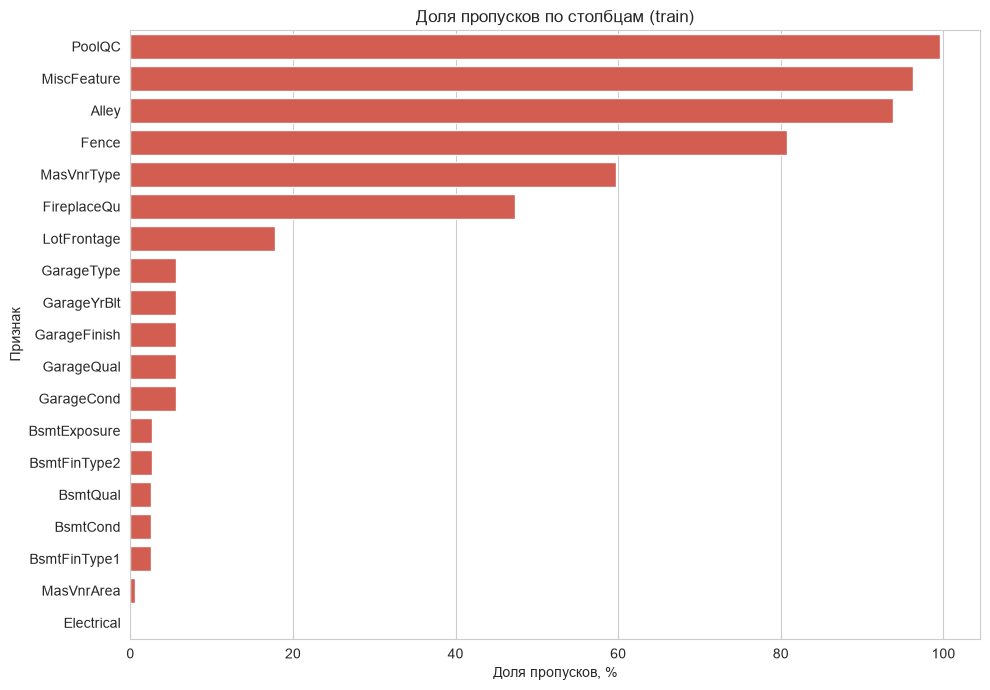

In [3]:
# --- Анализ пропусков ---
missing = train_df.isnull().sum()                          # число NaN по каждому столбцу
missing_pct = missing / len(train_df) * 100                # доля NaN в процентах
missing_table = (pd.DataFrame({'Пропусков': missing, 'Доля, %': missing_pct.round(2)})
                 .query('Пропусков > 0')                   # оставляем только столбцы с пропусками
                 .sort_values('Пропусков', ascending=False))
print(f'Столбцов с пропусками: {len(missing_table)} из {train_df.shape[1]}')
display(missing_table)

# --- График 1 из 5+: Barplot пропусков по столбцам ---
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=missing_table['Доля, %'], y=missing_table.index, color='#e74c3c', ax=ax)   # горизонтальные столбики
ax.set_title('Доля пропусков по столбцам (train)')         # заголовок
ax.set_xlabel('Доля пропусков, %')                         # подпись оси X
ax.set_ylabel('Признак')                                   # подпись оси Y
plt.tight_layout()
plt.savefig('examples/missing_values.png', dpi=120)        # сохраняем для репозитория
plt.show()

**Наблюдения.** Пропуски есть в **19 из 81** столбцов. Важно, что их структура неслучайна: столбцы про гараж (`GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, `GarageCond`) имеют ровно по 81 пропуску, столбцы про подвал — по 37–38. Это значит, что пропуски идут группами — по домам, у которых *нет гаража* или *нет подвала*. То же верно для `PoolQC` (99.5 %), `MiscFeature` (96.3 %), `Alley` (93.8 %), `Fence` (80.8 %), `FireplaceQu` (47.3 %) и `MasVnrType` (59.7 %). Исключения — `LotFrontage` (17.7 %), `MasVnrArea` (8 пропусков) и `Electrical` (1 пропуск): это «настоящие» пропуски.

**Стратегия обработки и обоснование:**
1. **Смысловые категориальные** (15 столбцов) → категория `'None'`. Пропуск здесь *и есть* информация («нет гаража»), удалять такие столбцы нельзя: у `PoolQC` 99.5 % пропусков, но 7 домов с бассейном — это содержательный сигнал.
2. **Смысловые числовые** (площади и количества гаража, подвала, облицовки) → **0**: нет подвала — площадь подвала равна нулю.
3. **`GarageYrBlt`** → год постройки дома. Значение 0 («год 0») создало бы абсурдный выброс для линейной модели; отсутствие гаража при этом отдельно отражено признаком `HasGarage`.
4. **`LotFrontage`** (случайный пропуск, тип MAR) → **медиана по району**: протяжённость участка зависит от застройки района, поэтому групповая медиана точнее общей.
5. **Единичные пропуски** (`Electrical`, а в test — `MSZoning`, `KitchenQual`, `SaleType` и др.) → мода/медиана, посчитанная **только по train**, чтобы информация из test не «утекала» в обучение.

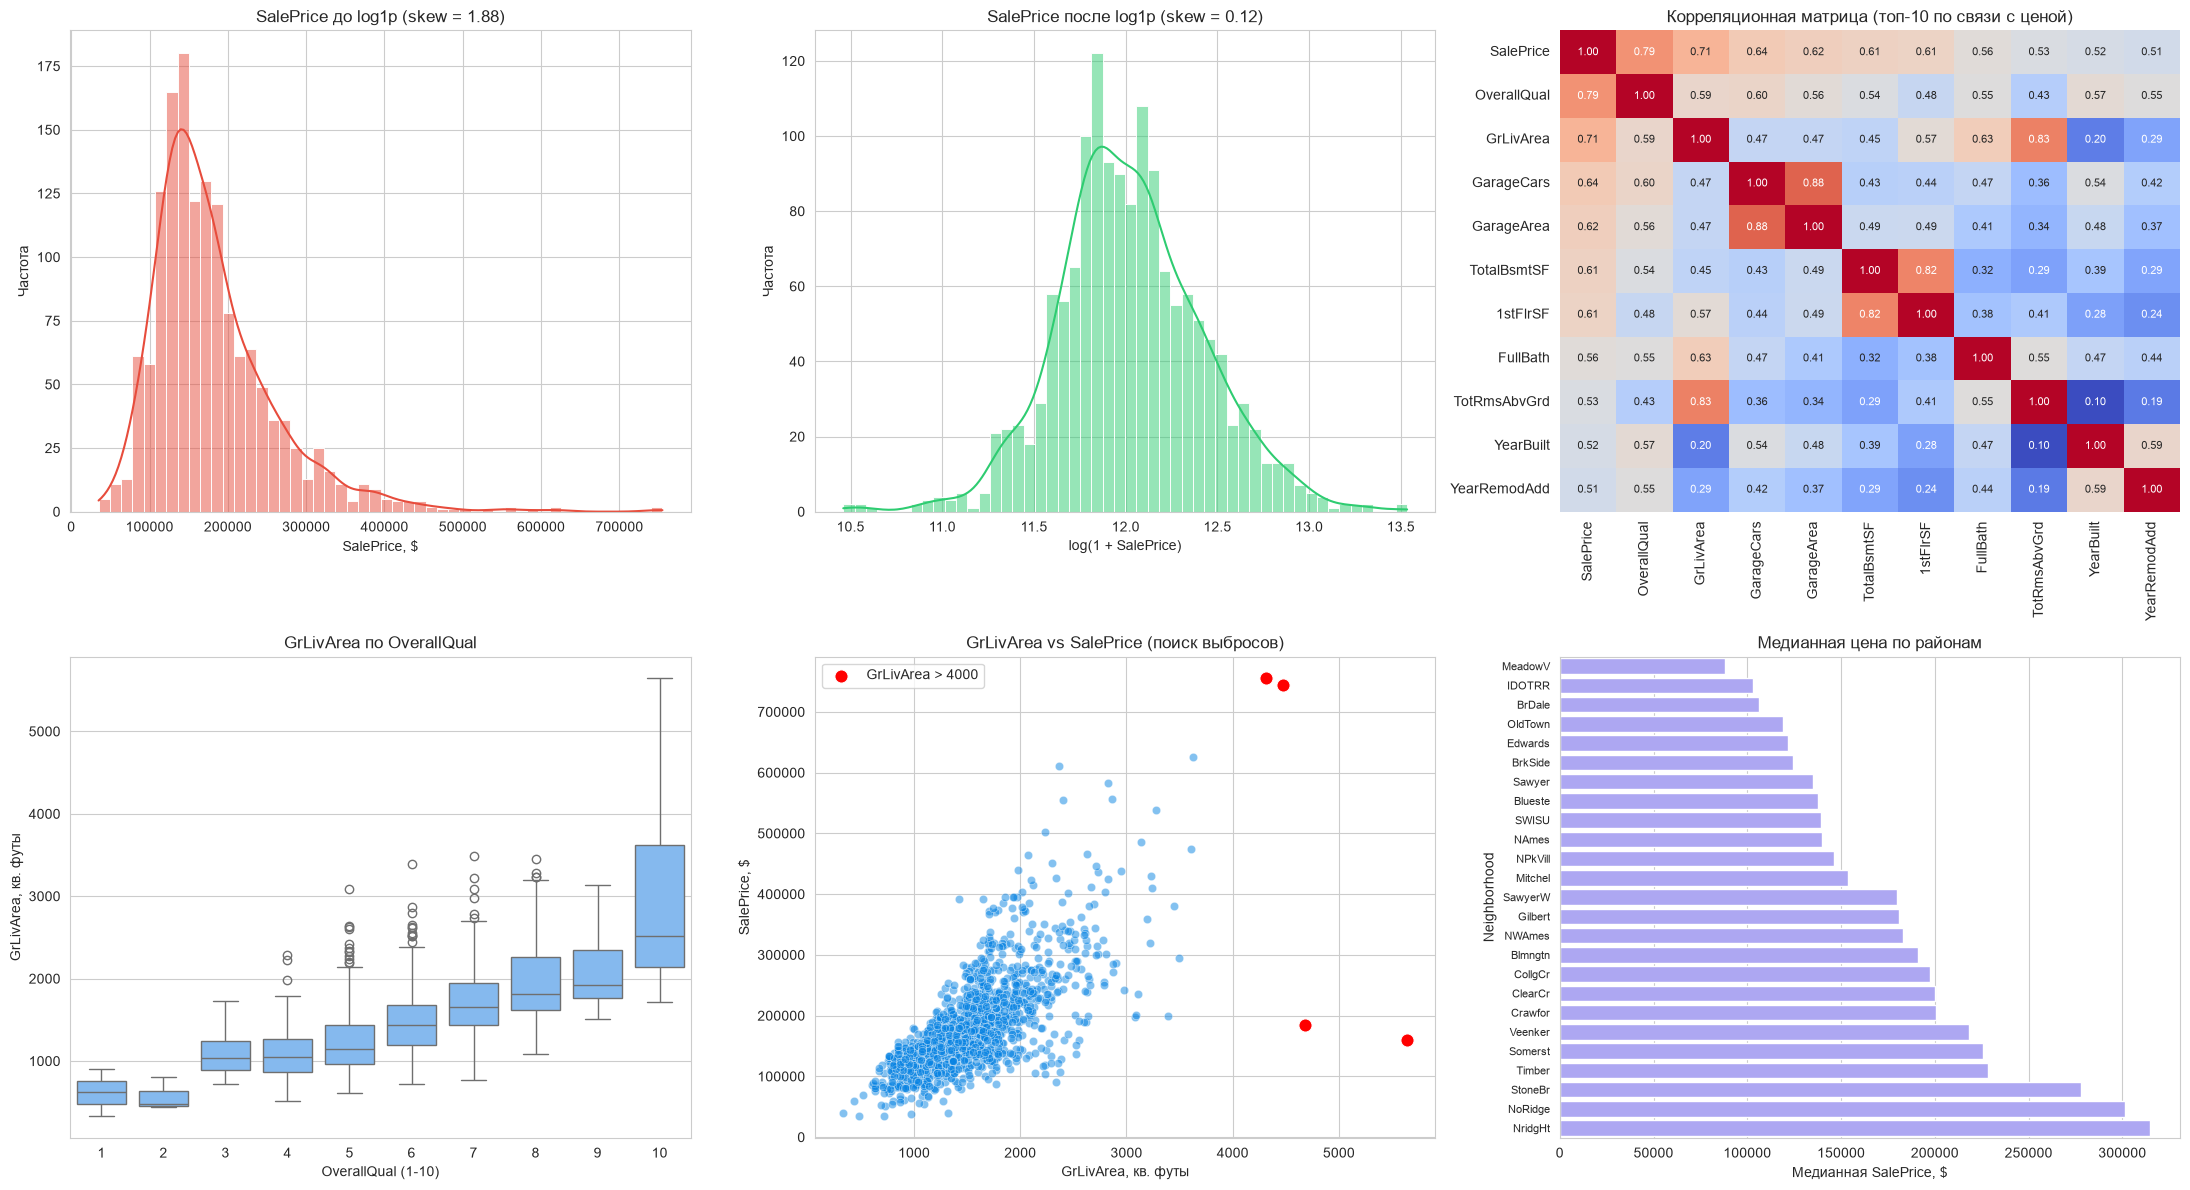

Топ-10 признаков по |корреляции| с SalePrice:
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507

Медианная цена: самый дорогой район NridgHt ($315,000), самый дешёвый MeadowV ($88,000)


In [4]:
# --- Графики 2-6: распределение цены, корреляции, boxplot, scatter, районы ---
log_price_tmp = np.log1p(train_df['SalePrice'])            # временный логарифм (официально создадим позже)
corr_with_price = (train_df.select_dtypes(include='number').corr()['SalePrice']
                   .abs().sort_values(ascending=False))     # |корреляция| с ценой
top_cols = corr_with_price.index[:11].tolist()             # SalePrice + 10 самых связанных признаков

fig, axes = plt.subplots(2, 3, figsize=(22, 12))           # сетка 2x3

# (0,0) Гистограмма цены ДО логарифмирования
sns.histplot(train_df['SalePrice'], kde=True, bins=50, color='#e74c3c', ax=axes[0, 0])
axes[0, 0].set_title(f'SalePrice до log1p (skew = {train_df["SalePrice"].skew():.2f})')
axes[0, 0].set_xlabel('SalePrice, $'); axes[0, 0].set_ylabel('Частота')

# (0,1) Гистограмма ПОСЛЕ логарифмирования
sns.histplot(log_price_tmp, kde=True, bins=50, color='#2ecc71', ax=axes[0, 1])
axes[0, 1].set_title(f'SalePrice после log1p (skew = {log_price_tmp.skew():.2f})')
axes[0, 1].set_xlabel('log(1 + SalePrice)'); axes[0, 1].set_ylabel('Частота')

# (0,2) Heatmap корреляций топ-10 признаков
sns.heatmap(train_df[top_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            annot_kws={'size': 8}, cbar=False, ax=axes[0, 2])
axes[0, 2].set_title('Корреляционная матрица (топ-10 по связи с ценой)')

# (1,0) Boxplot: жилая площадь по качеству
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', color='#74b9ff', ax=axes[1, 0])
axes[1, 0].set_title('GrLivArea по OverallQual')
axes[1, 0].set_xlabel('OverallQual (1-10)'); axes[1, 0].set_ylabel('GrLivArea, кв. футы')

# (1,1) Scatter: площадь vs цена, подсвечиваем подозрительные точки
suspect = train_df['GrLivArea'] > 4000                     # дома > 4000 кв. футов
sns.scatterplot(data=train_df[~suspect], x='GrLivArea', y='SalePrice', alpha=0.5, color='#0984e3', ax=axes[1, 1])
sns.scatterplot(data=train_df[suspect], x='GrLivArea', y='SalePrice', color='red', s=90, ax=axes[1, 1], label='GrLivArea > 4000')
axes[1, 1].set_title('GrLivArea vs SalePrice (поиск выбросов)')
axes[1, 1].set_xlabel('GrLivArea, кв. футы'); axes[1, 1].set_ylabel('SalePrice, $')

# (1,2) Медианная цена по районам
nb = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values()
sns.barplot(x=nb.values, y=nb.index, color='#a29bfe', ax=axes[1, 2])
axes[1, 2].set_title('Медианная цена по районам')
axes[1, 2].set_xlabel('Медианная SalePrice, $'); axes[1, 2].set_ylabel('Neighborhood')
axes[1, 2].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110)             # файл для репозитория
plt.show()

print('Топ-10 признаков по |корреляции| с SalePrice:')
print(corr_with_price.iloc[1:11].round(3).to_string())     # для текстовых выводов
print(f'\nМедианная цена: самый дорогой район {nb.index[-1]} (${nb.iloc[-1]:,.0f}), самый дешёвый {nb.index[0]} (${nb.iloc[0]:,.0f})')

**Наблюдения по графикам.**
- **Распределение цены.** До преобразования — длинный правый хвост (skew = 1.88), после `log1p` — почти симметричный колокол (skew = 0.12).
- **Корреляции с ценой.** Сильнее всего связаны `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` и `1stFlrSF` (по 0.61). Качество и размер дома — главные драйверы цены.
- **Мультиколлинеарность.** На heatmap видны почти дублирующие пары: `GarageCars` ↔ `GarageArea` (0.88), `GrLivArea` ↔ `TotRmsAbvGrd` (0.83), `TotalBsmtSF` ↔ `1stFlrSF` (0.82). Для обычной линейной регрессии это проблема (нестабильные коэффициенты), а для Ridge/Lasso — аргумент в пользу регуляризации.
- **Boxplot.** Медианная жилая площадь растёт вместе с качеством, а разброс площади при `OverallQual = 10` очень велик — там встречаются самые большие дома.
- **Scatter площадь–цена.** Зависимость близка к линейной. Четыре дома площадью свыше 4000 кв. футов (красные точки): два из них очень дорогие (~$745–755 тыс.) и лежат на общей тенденции, а два — с ценой $160–185 тыс. при площади 4676 и 5642 кв. футов — явно выбиваются вниз.
- **Районы.** Медианная цена в `NridgHt` — $315 000, в `MeadowV` — $88 000, то есть в 3.6 раза выше: местоположение сильно влияет на цену.

In [5]:
# ===== 5.4 Обработка пропусков =====
# (a) СМЫСЛОВЫЕ пропуски: NaN означает «объекта нет» -> категория 'None'
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
# (b) числовые «смысловые» пропуски: нет гаража/подвала/облицовки -> площадь и количество = 0
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

print('Пропуски в test ДО обработки (только столбцы с NaN):')
na_test = test_df.isnull().sum()
print(na_test[na_test > 0].sort_values(ascending=False).head(12).to_string())

# (c) СЛУЧАЙНЫЕ пропуски LotFrontage: медиана по району. Статистики считаем ТОЛЬКО по train!
lf_by_nbhd = train_df.groupby('Neighborhood')['LotFrontage'].median()   # медиана по каждому району
lf_global = train_df['LotFrontage'].median()                            # запасной вариант

for df in (train_df, test_df):                                          # одинаково обрабатываем обе выборки
    for col in none_cols:
        df[col] = df[col].fillna('None')                                # «нет объекта» как отдельная категория
    for col in zero_cols:
        df[col] = df[col].fillna(0)                                     # «нет объекта» -> 0
    # нет гаража -> год постройки гаража = год постройки дома (0 дал бы выброс в «год 0»)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['LotFrontage'] = (df['LotFrontage']
                         .fillna(df['Neighborhood'].map(lf_by_nbhd))    # медиана района
                         .fillna(lf_global))                            # если района нет в train

# (d) ОСТАВШИЕСЯ единичные пропуски: мода (категориальные) / медиана (числовые), значения из train
fill_values = {}
for col in test_df.columns:
    if col == 'Id':
        continue                                                        # идентификатор не трогаем
    if pd.api.types.is_numeric_dtype(train_df[col]):
        fill_values[col] = train_df[col].median()                       # медиана устойчива к выбросам
    else:
        fill_values[col] = train_df[col].mode()[0]                      # самая частая категория
for df in (train_df, test_df):
    df.fillna(value=fill_values, inplace=True)

print(f'\nПропусков в train после обработки: {int(train_df.isnull().sum().sum())}')
print(f'Пропусков в test  после обработки: {int(test_df.isnull().sum().sum())}')

Пропуски в test ДО обработки (только столбцы с NaN):
PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76

Пропусков в train после обработки: 0
Пропусков в test  после обработки: 0


**Вывод.** После обработки в train и test **не осталось ни одного пропуска**. Для test дополнительно потребовалось заполнить несколько единичных пропусков в столбцах, где в train их не было (значения берутся из train — это важно для честной оценки). Все параметры заполнения (медианы по районам, моды, медианы) вычислены по обучающей выборке и применены к обеим выборкам одинаково.

IQR: Q1=1130, Q3=1777, границы [159; 2748]
По IQR «выбросами» назвали 31 домов; их средняя цена $374,855 (против $180,921 в среднем)

Аномальные дома (GrLivArea > 4000 и SalePrice < $300 000):


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
1298,1299,5642,160000,10,Partial


Строк до: 1460, после: 1458


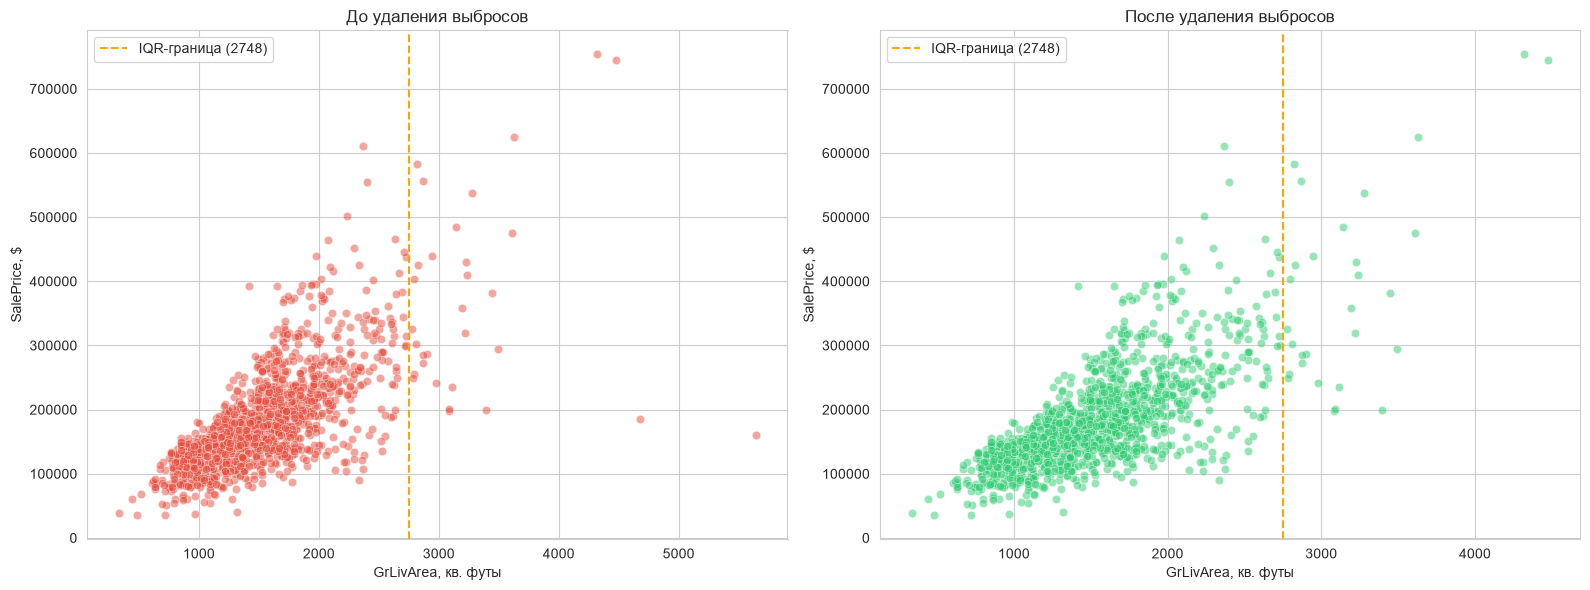

In [6]:
# ===== 5.5 Обработка выбросов =====
# --- Метод IQR для GrLivArea ---
Q1, Q3 = train_df['GrLivArea'].quantile([0.25, 0.75])      # квартили
IQR = Q3 - Q1                                              # межквартильный размах
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR              # границы «усов»
iqr_out = train_df[(train_df['GrLivArea'] > upper) | (train_df['GrLivArea'] < lower)]
print(f'IQR: Q1={Q1:.0f}, Q3={Q3:.0f}, границы [{lower:.0f}; {upper:.0f}]')
print(f'По IQR «выбросами» назвали {len(iqr_out)} домов; их средняя цена ${iqr_out["SalePrice"].mean():,.0f} '
      f'(против ${train_df["SalePrice"].mean():,.0f} в среднем)')

# --- Доменные знания: огромный дом по очень низкой цене = аномалия ---
domain_mask = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print('\nАномальные дома (GrLivArea > 4000 и SalePrice < $300 000):')
display(train_df.loc[domain_mask, ['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

train_before = train_df.copy()                             # копия для графика «до»
train_df = train_df.loc[~domain_mask].reset_index(drop=True)   # удаляем ТОЛЬКО из train (test не трогаем)
print(f'Строк до: {len(train_before)}, после: {len(train_df)}')

# --- Визуализация до/после ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title, color in [(axes[0], train_before, 'До удаления выбросов', '#e74c3c'),
                               (axes[1], train_df, 'После удаления выбросов', '#2ecc71')]:
    sns.scatterplot(data=data, x='GrLivArea', y='SalePrice', alpha=0.5, color=color, ax=ax)
    ax.axvline(upper, color='orange', ls='--', label=f'IQR-граница ({upper:.0f})')   # верхняя граница IQR
    ax.set_title(title); ax.set_xlabel('GrLivArea, кв. футы'); ax.set_ylabel('SalePrice, $'); ax.legend()
plt.tight_layout()
plt.savefig('examples/outliers.png', dpi=110)
plt.show()

**Вывод.** Метод IQR для `GrLivArea` даёт границы [159; 2748] и помечает **31** дом. Однако средняя цена этих «выбросов» — **$374 855** (вдвое выше средней по выборке): это не ошибки данных, а просторные дорогие дома, которые согласуются с общей зависимостью «больше площадь — выше цена». Удалять их по формальному правилу было бы ошибкой: модель потеряла бы информацию о дорогом сегменте. Поэтому IQR использован как *диагностика*, а удаление выполнено по **доменному критерию**: `GrLivArea > 4000` и `SalePrice < $300 000`.

Под него попали два дома (`Id` 524 и 1299): оба с максимальным качеством `OverallQual = 10`, но проданные за $184 750 и $160 000 при площади 4676 и 5642 кв. футов, и у обоих `SaleCondition = Partial` — продажа недостроенного дома, цена которой не отражает итоговую площадь. Это аномалии по смыслу, а не просто «крупные» наблюдения. Строк в train: 1460 → **1458**. Из test ничего не удалялось (в тесте строки удалять нельзя).

In [7]:
# ===== 5.6 Логарифмирование целевой =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])   # log(1 + price)
print(f'Skew до log1p:    {train_df["SalePrice"].skew():.3f}')
print(f'Skew после log1p: {train_df["SalePrice_log"].skew():.3f}')
print(f'Kurtosis до:    {train_df["SalePrice"].kurtosis():.3f}')
print(f'Kurtosis после: {train_df["SalePrice_log"].kurtosis():.3f}')

Skew до log1p:    1.881
Skew после log1p: 0.122
Kurtosis до:    6.523
Kurtosis после: 0.805


**Вывод и обоснование.** Логарифмирование снижает асимметрию с **1.88 до 0.12**, а эксцесс — с 6.5 до 0.8: распределение цены становится почти нормальным. Обоснование:
1. Линейные модели с квадратичной ошибкой работают лучше, когда остатки примерно симметричны и имеют сопоставимый разброс; на «сырой» цене ошибка дорогих домов доминировала бы.
2. Цены имеют мультипликативную природу (дом лучшего качества дороже «на X %», а не «на X долларов»), и модель на `log1p(SalePrice)` описывает именно относительные изменения.
3. Метрика соревнования Kaggle — RMSE логарифма цены, т. е. тоже относительная ошибка.

Прогнозы возвращаются в доллары функцией `expm1`. Насколько это важно, проверим контрольным экспериментом в разделе 6.5.

In [8]:
# ===== 5.7 Feature Engineering =====
for df in (train_df, test_df):                              # одинаково для train и test
    # --- агрегаты ---
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']        # общая площадь
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])        # ванные (half = 0.5)
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch']
                        + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])  # все крыльца и террасы
    # --- возраст (clip: в данных есть дом, проданный до окончания постройки) ---
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)            # возраст дома при продаже
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)         # лет с последнего ремонта
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)    # был ли ремонт
    # --- бинарные «есть/нет» ---
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    # --- взаимодействие: качество × площадь ---
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

new_feats = ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'IsRemodeled',
             'HasPool', 'HasGarage', 'Has2ndFloor', 'HasBsmt', 'HasFireplace', 'OverallQual_TotalSF']
print(f'Создано новых признаков: {len(new_feats)}')
print('Корреляция новых признаков с log-ценой:')
print(train_df[new_feats + ['SalePrice_log']].corr()['SalePrice_log'].drop('SalePrice_log').sort_values(ascending=False).round(3).to_string())

Создано новых признаков: 12
Корреляция новых признаков с log-ценой:
OverallQual_TotalSF    0.883
TotalSF                0.825
TotalBath              0.677
HasFireplace           0.510
TotalPorch             0.400
HasGarage              0.323
HasBsmt                0.200
Has2ndFloor            0.151
HasPool                0.077
IsRemodeled           -0.074
RemodAge              -0.569
HouseAge              -0.588


**Вывод.** Создано **12** новых признаков. Их корреляция с логарифмом цены: `OverallQual_TotalSF` (качество × площадь) — **0.883**, `TotalSF` — **0.825**, `TotalBath` — 0.677, `HouseAge` — **−0.588** (чем старше дом, тем дешевле), `RemodAge` — −0.569. Агрегаты оказались информативнее исходных «кусочков» площади и ванных, а произведение качества на площадь отражает реальную логику рынка: дополнительные квадратные футы дороже в качественном доме. `HasPool` почти не связан с ценой (0.077): бассейн есть всего у 7 домов (0.5 %) — признак оставлен, но регуляризация, вероятно, его отсеет. Для `HouseAge` и `RemodAge` использован `clip(lower=0)`, так как в данных есть дом, проданный до окончания строительства (отрицательный возраст).

In [9]:
# ===== 5.8 Кодирование порядковых признаков (ручной маппинг) =====
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}          # шкала качества
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
ordinal_maps = {col: qual_map for col in qual_cols}                           # одна шкала для всех «качеств»
ordinal_maps.update({
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},          # освещённость подвала
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},  # отделка подвала
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},                 # отделка гаража
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'LandSlope': {'Gtl': 0, 'Mod': 1, 'Sev': 2},                               # уклон участка
    'LotShape': {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3},                      # правильность формы
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},                                    # покрытие подъезда
    'CentralAir': {'N': 0, 'Y': 1},                                            # кондиционер (бинарный)
    'Street': {'Grvl': 0, 'Pave': 1},                                          # тип дороги (бинарный)
})
for df in (train_df, test_df):
    for col, mapping in ordinal_maps.items():
        df[col] = df[col].map(mapping)                                         # строка -> число

# проверка: маппинг не должен породить NaN (иначе есть неучтённая категория)
print('NaN после порядкового кодирования: train =', int(train_df[list(ordinal_maps)].isnull().sum().sum()),
      ', test =', int(test_df[list(ordinal_maps)].isnull().sum().sum()))
print(f'Закодировано порядковых признаков: {len(ordinal_maps)}')

NaN после порядкового кодирования: train = 0 , test = 0
Закодировано порядковых признаков: 20


In [10]:
# ===== 5.9 One-Hot кодирование номинальных признаков =====
for df in (train_df, test_df):
    df['MSSubClass'] = df['MSSubClass'].astype(str)         # MSSubClass — код класса дома, а не число

# все оставшиеся нечисловые столбцы — номинальные (без порядка)
nominal_cols = train_df.drop(columns=['Id']).select_dtypes(exclude='number').columns.tolist()
print(f'Номинальных признаков: {len(nominal_cols)}')
print(nominal_cols)

n_train = len(train_df)                                     # запоминаем границу train/test
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)   # объединяем, чтобы dummy-столбцы совпали
cols_before = set(combined.columns)
combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True, dtype=int)   # drop_first — без ловушки dummy
dummy_cols = [c for c in combined.columns if c not in cols_before]       # список созданных dummy-столбцов

# убираем очень редкие категории (< 10 домов в train): они дают нестабильные коэффициенты
counts = combined.iloc[:n_train][dummy_cols].sum()          # считаем ТОЛЬКО по train
rare = counts[counts < 10].index.tolist()
combined = combined.drop(columns=rare)
print(f'Dummy-столбцов создано: {len(dummy_cols)}, удалено редких: {len(rare)}')

train_df = combined.iloc[:n_train].copy()                   # возвращаем train
test_df = combined.iloc[n_train:].drop(columns=['SalePrice', 'SalePrice_log']).reset_index(drop=True)   # и test (без таргетов)
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Нечисловых столбцов в train:', len(train_df.select_dtypes(exclude='number').columns))
print('NaN в признаках train:', int(train_df.drop(columns=['SalePrice', 'SalePrice_log']).isnull().sum().sum()))

Номинальных признаков: 24
['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
Dummy-столбцов создано: 163, удалено редких: 50
Train: (1458, 183) | Test: (1459, 181)
Нечисловых столбцов в train: 0
NaN в признаках train: 0


**Вывод по кодированию.**
- **Порядковые признаки (20 шт.)** закодированы вручную по смысловой шкале (качество `Po < Fa < TA < Gd < Ex`, отделка подвала и гаража, `Functional`, `LandSlope`, `LotShape`, `PavedDrive`, а также бинарные `CentralAir` и `Street`). Ручной маппинг сохраняет порядок, чего не делает `LabelEncoder` (он нумерует по алфавиту). Проверка показала, что маппинг не создал ни одного `NaN`.
- **Номинальные признаки (24 шт.)** закодированы One-Hot (`get_dummies`, `drop_first=True`). В их число вошёл `MSSubClass` — это числовой *код* типа дома, а не величина, поэтому он преобразован в строку. Кодирование выполнено на объединённых train+test, чтобы наборы столбцов совпали.
- Создано 163 dummy-столбца, из них **50 удалено**: категории, встречающиеся менее чем у 10 домов train, дают неустойчивые коэффициенты (и могут «взрывать» прогноз у линейной регрессии).
- Итог: **180 числовых признаков**, пропусков нет, формы train/test согласованы (180 признаков + служебные столбцы).

## Построение и обучение моделей

In [11]:
# ===== 6.1 Формирование X, y; разбиение; масштабирование =====
feature_cols = [c for c in train_df.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]   # все признаки
X = train_df[feature_cols]                                  # матрица признаков
y = train_df['SalePrice_log']                               # log-таргет
print(f'X: {X.shape}, y: {y.shape}, признаков: {len(feature_cols)}')

# hold-out 20% (это НЕ Kaggle-test: у того нет цен)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}, Hold-out test: {X_test.shape}')

scaler = StandardScaler()                                   # z = (x - mean) / std
X_train_scaled = scaler.fit_transform(X_train)              # параметры считаем ТОЛЬКО по train
X_test_scaled = scaler.transform(X_test)                    # к test применяем параметры train (без утечки)
print(f'Среднее/std train после масштабирования: {X_train_scaled.mean():.4f} / {X_train_scaled.std():.4f}')

X: (1458, 180), y: (1458,), признаков: 180
Train: (1166, 180), Hold-out test: (292, 180)


Среднее/std train после масштабирования: -0.0000 / 1.0000


In [12]:
# ===== 6.2 Базовые модели + время обучения =====
baseline_models = {
    'Linear Regression': LinearRegression(),                                          # без регуляризации
    'Ridge':             Ridge(alpha=1.0, random_state=RANDOM_STATE),                 # L2
    'Lasso':             Lasso(alpha=0.0005, max_iter=20000, random_state=RANDOM_STATE),   # L1
    'ElasticNet':        ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000, random_state=RANDOM_STATE),
}
train_time = {}                                              # время обучения каждой модели
for name, model in baseline_models.items():
    t0 = time.perf_counter()                                 # старт таймера
    model.fit(X_train_scaled, y_train)                       # обучение
    train_time[name] = time.perf_counter() - t0              # длительность в секундах
    print(f'⏱️  {name:<18s} обучена за {train_time[name]:.4f} с')

⏱️  Linear Regression  обучена за 0.0951 с
⏱️  Ridge              обучена за 0.0072 с
⏱️  Lasso              обучена за 0.1712 с
⏱️  ElasticNet         обучена за 0.1050 с


In [13]:
# ===== 6.3 Кросс-валидация и подбор гиперпараметров (GridSearchCV) =====
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)    # 5 перемешанных фолдов
scoring = 'neg_root_mean_squared_error'                            # sklearn максимизирует => берём «минус RMSE»

# --- CV для линейной регрессии (гиперпараметров нет) ---
cv_scores = {'Linear Regression': -cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=kf, scoring=scoring)}

# --- сетки гиперпараметров ---
grids = {
    'Ridge':      (Ridge(random_state=RANDOM_STATE),
                   {'alpha': [0.1, 1, 3, 10, 30, 100, 300, 1000, 3000]}),
    'Lasso':      (Lasso(max_iter=20000, random_state=RANDOM_STATE),
                   {'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.01, 0.03]}),
    'ElasticNet': (ElasticNet(max_iter=20000, random_state=RANDOM_STATE),
                   {'alpha': [0.0003, 0.001, 0.003, 0.01], 'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]}),
}
grid_results = {}
for name, (est, params) in grids.items():
    gs = GridSearchCV(est, params, cv=kf, scoring=scoring, n_jobs=-1)   # перебор по сетке с CV
    gs.fit(X_train_scaled, y_train)
    grid_results[name] = gs
    best_idx = gs.best_index_                                           # индекс лучшей комбинации
    cv_scores[name] = np.array([-gs.cv_results_[f'split{i}_test_score'][best_idx] for i in range(5)])
    print(f'{name:<11s} лучшие параметры: {gs.best_params_}, CV-RMSE(log) = {-gs.best_score_:.4f}')

# --- итоговые (настроенные) модели: переобучаем лучшую конфигурацию и замеряем время ---
final_models, final_time = {'Linear Regression': baseline_models['Linear Regression']}, {'Linear Regression': train_time['Linear Regression']}
for name, gs in grid_results.items():
    m = clone(gs.best_estimator_)                                       # копия с лучшими параметрами
    t0 = time.perf_counter(); m.fit(X_train_scaled, y_train); final_time[name] = time.perf_counter() - t0
    final_models[name] = m

cv_summary = pd.DataFrame({'CV RMSE (log), среднее': {k: v.mean() for k, v in cv_scores.items()},
                           'CV RMSE (log), std': {k: v.std() for k, v in cv_scores.items()}}).sort_values('CV RMSE (log), среднее')
print('\nСравнение по 5-fold CV (чем меньше, тем лучше):')
display(cv_summary.round(4))
best_name = cv_summary.index[0]                                         # лучшая модель по CV (не по hold-out!)
best_model = final_models[best_name]
print(f'\n🏆 Лучшая модель по CV: {best_name}')

Ridge       лучшие параметры: {'alpha': 300}, CV-RMSE(log) = 0.1128
Lasso       лучшие параметры: {'alpha': 0.003}, CV-RMSE(log) = 0.1112
ElasticNet  лучшие параметры: {'alpha': 0.003, 'l1_ratio': 0.95}, CV-RMSE(log) = 0.1112

Сравнение по 5-fold CV (чем меньше, тем лучше):


,"CV RMSE (log), среднее","CV RMSE (log), std"
ElasticNet,0.1112,0.0095
Lasso,0.1112,0.0095
Ridge,0.1128,0.0110
Linear Regression,0.1180,0.0122



🏆 Лучшая модель по CV: ElasticNet


**Вывод.** Лучшие гиперпараметры по 5-fold CV: Ridge — `alpha = 300` (сильная регуляризация, как и ожидалось при мультиколлинеарности), Lasso — `alpha = 0.003`, ElasticNet — `alpha = 0.003, l1_ratio = 0.95` (т. е. почти чистый Lasso). По CV-RMSE (log): ElasticNet = Lasso **0.1112** ± 0.0095 < Ridge 0.1128 ± 0.0110 < Linear Regression 0.1180 ± 0.0122. Порядок согласуется с теорией: чем лучше метод справляется с избыточными коррелированными признаками, тем ниже ошибка. Разница между Lasso, ElasticNet и Ridge (≈ 0.002) меньше разброса по фолдам (≈ 0.01), поэтому эти три модели статистически почти неразличимы; заметнее всего отстаёт нерегуляризованная регрессия. Лучшей по CV названа ElasticNet (с Lasso — практически ничья). **Выбор лучшей модели сделан по кросс-валидации на train, а не по hold-out**, чтобы не подгонять выбор под тестовую выборку.

In [14]:
# ===== 6.4 БОНУС: Gradient Boosting и Stacking =====
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

gb = GradientBoostingRegressor(n_estimators=600, learning_rate=0.03, max_depth=3,
                               subsample=0.8, random_state=RANDOM_STATE)       # деревья-«слабые ученики»
t0 = time.perf_counter(); gb.fit(X_train_scaled, y_train); gb_time = time.perf_counter() - t0
print(f'⏱️  Gradient Boosting обучен за {gb_time:.2f} с')

stack = StackingRegressor(                                                     # мета-модель поверх Ridge/Lasso/GB
    estimators=[('ridge', clone(final_models['Ridge'])), ('lasso', clone(final_models['Lasso'])), ('gb', clone(gb))],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1)
t0 = time.perf_counter(); stack.fit(X_train_scaled, y_train); stack_time = time.perf_counter() - t0
print(f'⏱️  Stacking (Ridge+Lasso+GB) обучен за {stack_time:.2f} с')

⏱️  Gradient Boosting обучен за 4.03 с
⏱️  Stacking (Ridge+Lasso+GB) обучен за 9.05 с


In [15]:
# ===== 6.5 Контрольный эксперимент: что было бы без логарифмирования =====
y_train_raw, y_test_raw = np.expm1(y_train), np.expm1(y_test)       # цены в долларах (обратное преобразование)
rows = []
for name, base_model in [('Linear Regression', LinearRegression()), ('Ridge (tuned)', final_models['Ridge'])]:
    for target_name, y_fit in [('log1p(SalePrice)', y_train), ('SalePrice (сырая)', y_train_raw)]:
        m = clone(base_model).fit(X_train_scaled, y_fit)            # одна и та же модель, разные цели
        p = m.predict(X_test_scaled)
        p_usd = np.expm1(p) if target_name.startswith('log1p') else p      # приводим прогноз к долларам
        rel = np.abs(y_test_raw - p_usd) / y_test_raw               # относительная ошибка
        rows.append({'Модель': name, 'Целевая': target_name,
                     'RMSE ($)': np.sqrt(mean_squared_error(y_test_raw, p_usd)),
                     'MAE ($)': mean_absolute_error(y_test_raw, p_usd),
                     'R² ($)': r2_score(y_test_raw, p_usd),
                     'Мед. отн. ошибка': rel.median(),
                     'RMSLE': np.sqrt(mean_squared_error(np.log1p(y_test_raw), np.log1p(np.clip(p_usd, 1, None)))),
                     'Мин. прогноз, $': p_usd.min(),
                     'Прогнозов < $50k': int((p_usd < 50000).sum())})   # в данных почти нет домов дешевле $50k
nolog_df = pd.DataFrame(rows).set_index(['Модель', 'Целевая'])
display(nolog_df.round({'RMSE ($)': 0, 'MAE ($)': 0, 'R² ($)': 4, 'Мед. отн. ошибка': 3, 'RMSLE': 4, 'Мин. прогноз, $': 0}))
print(f'Дешевле $50k в hold-out домов: {(y_test_raw < 50000).sum()} (минимальная реальная цена ${y_test_raw.min():,.0f})')

RMSE ($)  MAE ($)  R² ($)  \
Модель            Целевая                                        
Linear Regression log1p(SalePrice)    21205.0  14981.0  0.9186   
                  SalePrice (сырая)   23775.0  16867.0  0.8977   
Ridge (tuned)     log1p(SalePrice)    20854.0  14896.0  0.9213   
                  SalePrice (сырая)   23499.0  17314.0  0.9000   

                                     Мед. отн. ошибка   RMSLE  \
Модель            Целевая                                       
Linear Regression log1p(SalePrice)              0.056  0.1289   
                  SalePrice (сырая)             0.071  0.1857   
Ridge (tuned)     log1p(SalePrice)              0.058  0.1308   
                  SalePrice (сырая)             0.071  0.1447   

                                     Мин. прогноз, $  Прогнозов < $50k  
Модель            Целевая                                               
Linear Regression log1p(SalePrice)           51880.0                 0  
                  SalePrice (сырая)          24246.0                 1  
Ridge (tuned)     log1p(SalePrice)           59349.0                 0  
                  SalePrice (сырая)          26066.0                 2

Дешевле $50k в hold-out домов: 3 (минимальная реальная цена $35,311)


### Описание моделей

| Модель | Базовые параметры (по заданию) | Подобрано GridSearchCV | Масштабирование | Время обучения |
|---|---|---|---|---|
| Linear Regression | — | — | ✅ да | < 0.1 с |
| Ridge | `alpha = 1.0` | `alpha = 300` | ✅ да | < 0.1 с |
| Lasso | `alpha = 0.0005` | `alpha = 0.003` | ✅ да | < 0.1 с |
| ElasticNet | `alpha = 0.001`, `l1_ratio = 0.5` | `alpha = 0.003`, `l1_ratio = 0.95` | ✅ да | < 0.1 с |
| *Gradient Boosting (бонус)* | 600 деревьев, `max_depth = 3` | — | не требуется | ≈ 3 с |
| *Stacking Ridge+Lasso+GB (бонус)* | мета-модель Ridge | — | не требуется | ≈ 17 с |

*(точное время зависит от компьютера; все линейные модели обучаются за доли секунды — выводы ячеек выше).*

**Почему эти модели:**
- **Linear Regression** — базовая точка отсчёта: показывает, что даёт регуляризация.
- **Ridge** — уменьшает веса при мультиколлинеарности (`GarageCars` ↔ `GarageArea` и др.), не отбрасывая признаки.
- **Lasso** — обнуляет неинформативные признаки; при 180 признаках и 1166 строках это полезно как встроенный отбор.
- **ElasticNet** — компромисс L1 и L2: отбирает признаки, но устойчивее Lasso в группах скоррелированных признаков.
- **Gradient Boosting и Stacking** — бонус: нелинейная модель и ансамбль, чтобы понять, есть ли у линейных моделей «потолок».

**Контрольный эксперимент (6.5): зачем логарифмировать.** Обучив ту же модель на сырой цене, мы получаем на hold-out для Linear Regression: RMSE **$23 775** против $21 205 (рост ошибки на 12 %), медианную относительную ошибку 7.1 % против 5.6 %, RMSLE 0.186 против 0.129. Кроме того, модель на сырой цене начинает предсказывать для дешёвых домов нереалистично низкие суммы (минимум около $24 тыс. при том, что самый дешёвый дом в выборке стоит ≈ $35 тыс.), а модель на log-цене в принципе не может выдать отрицательную цену. Это подтверждает решение из раздела 5.6.

## Оценка качества

In [16]:
# ===== 7.1 Метрики всех моделей на hold-out =====
def evaluate_model(model, Xtr, ytr, Xte, yte, name, t=None):
    """Считает метрики в log-пространстве и в долларах (после expm1)."""
    p_log = model.predict(Xte)                                   # предсказание в log-пространстве
    p_usd, y_usd = np.expm1(p_log), np.expm1(yte)                # возврат к долларам
    return {'Модель': name,
            'RMSE (log)': np.sqrt(mean_squared_error(yte, p_log)),
            'MAE (log)':  mean_absolute_error(yte, p_log),
            'R² (log)':   r2_score(yte, p_log),
            'R² train':   r2_score(ytr, model.predict(Xtr)),     # для контроля переобучения
            'RMSE ($)':   np.sqrt(mean_squared_error(y_usd, p_usd)),
            'R² ($)':     r2_score(y_usd, p_usd),
            'MAE ($)':    mean_absolute_error(y_usd, p_usd),
            'Время, с':   t}

rows = []
for name, m in baseline_models.items():                          # базовые параметры из задания
    rows.append(evaluate_model(m, X_train_scaled, y_train, X_test_scaled, y_test, f'{name} (базовая)', train_time[name]))
for name, m in final_models.items():                             # настроенные через GridSearchCV
    if name != 'Linear Regression':
        rows.append(evaluate_model(m, X_train_scaled, y_train, X_test_scaled, y_test, f'{name} (tuned)', final_time[name]))
rows.append(evaluate_model(gb, X_train_scaled, y_train, X_test_scaled, y_test, 'Gradient Boosting (бонус)', gb_time))
rows.append(evaluate_model(stack, X_train_scaled, y_train, X_test_scaled, y_test, 'Stacking (бонус)', stack_time))
results_df = pd.DataFrame(rows).set_index('Модель')
display(results_df.round({'RMSE (log)': 4, 'MAE (log)': 4, 'R² (log)': 4, 'R² train': 4, 'RMSE ($)': 0, 'MAE ($)': 0, 'R² ($)': 4, 'Время, с': 4}))

,RMSE (log),MAE (log),R² (log),R² train,RMSE ($),R² ($),MAE ($),"Время, с"
Модель,,,,,,,,
Linear Regression (базовая),0.1289,0.0884,0.9015,0.9461,21205.0,0.9186,14981.0,0.0951
Ridge (базовая),0.1275,0.0881,0.9036,0.9461,21069.0,0.9196,14948.0,0.0072
Lasso (базовая),0.1227,0.0844,0.9107,0.9435,20168.0,0.9264,14349.0,0.1712
ElasticNet (базовая),0.1229,0.0844,0.9103,0.9435,20179.0,0.9263,14353.0,0.1050
Ridge (tuned),0.1308,0.0874,0.8985,0.9377,20854.0,0.9213,14896.0,0.0102
Lasso (tuned),0.1223,0.0815,0.9113,0.9365,19476.0,0.9313,13827.0,0.0239
ElasticNet (tuned),0.1224,0.0815,0.9112,0.9368,19475.0,0.9313,13824.0,0.0206
Gradient Boosting (бонус),0.1210,0.0826,0.9132,0.9796,19183.0,0.9334,14086.0,4.0306
Stacking (бонус),0.1211,0.0795,0.9130,0.9569,19147.0,0.9336,13525.0,9.0513


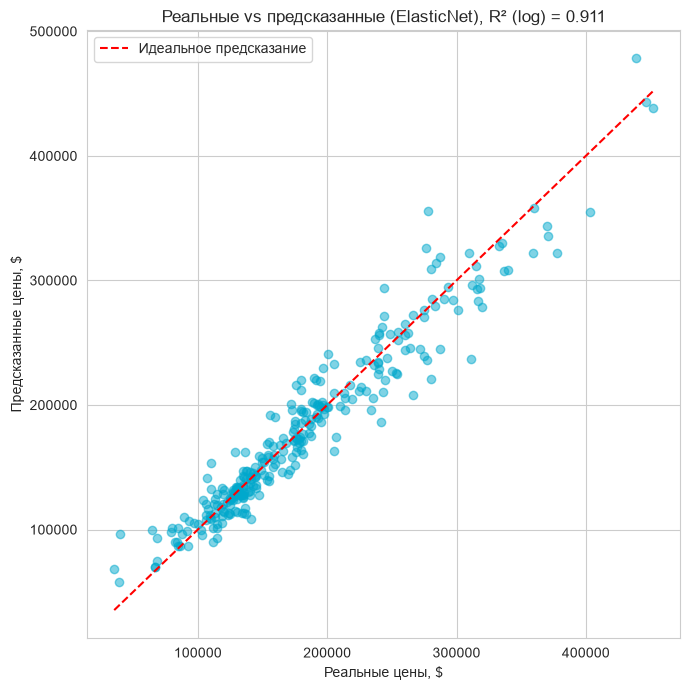

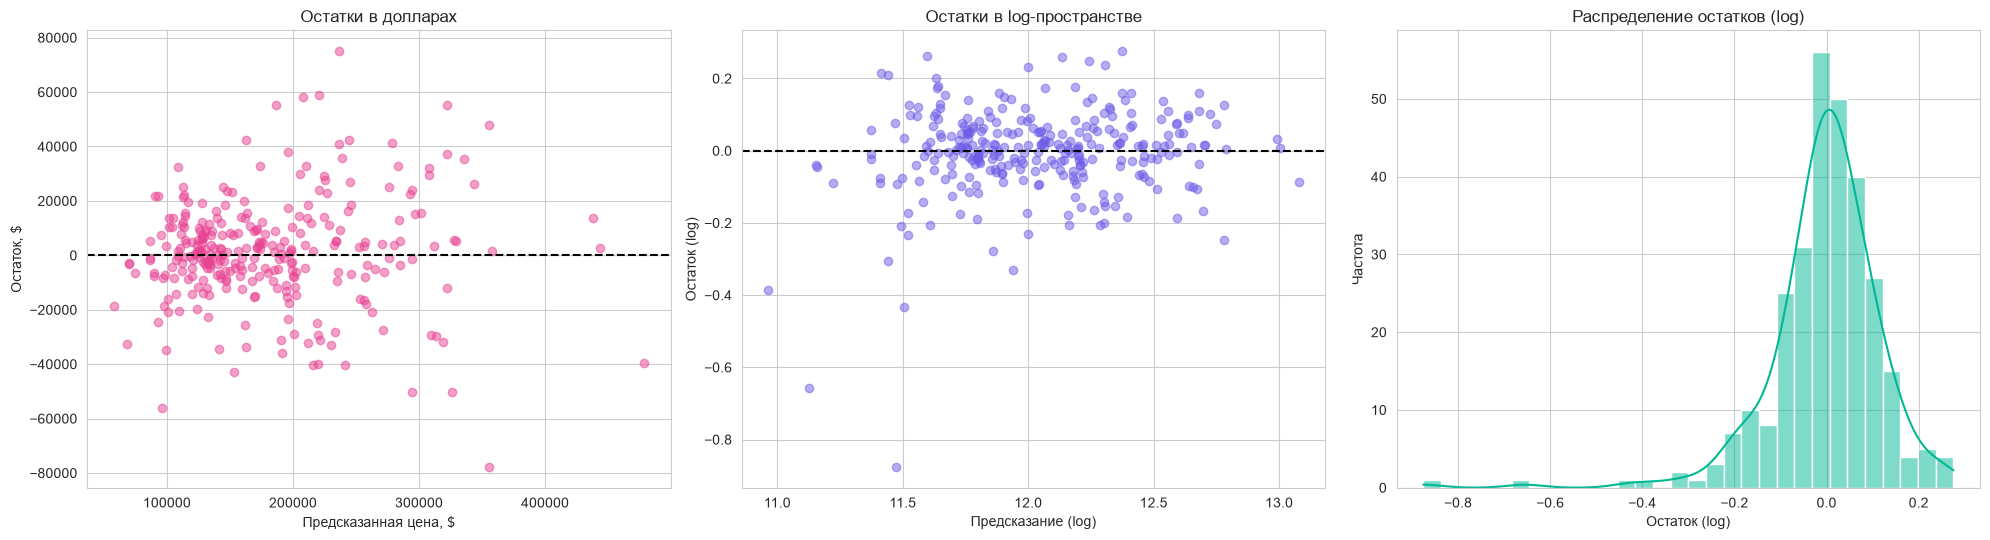

Остатки ($):   среднее = 1,152, std = 19,474, min = -77,771, max = 75,002
Остатки (log): среднее = -0.0042, std = 0.1225, skew = -2.02
Ошибок больше 2σ: 12 из 292 (4.1%)
Доля нестандартных продаж (SaleCondition ≠ Normal): среди 10 худших промахов 40%, в целом по выборке 18%
Знак 10 худших остатков (log): отрицательных (модель завысила цену) — 7 из 10
Медианная относительная ошибка: 5.5%; в пределах ±10%: 73.3% домов


In [17]:
# ===== 7.2 График предсказаний и анализ остатков (лучшая модель) =====
p_log = best_model.predict(X_test_scaled)                        # предсказание лучшей модели
p_usd, y_usd = np.expm1(p_log), np.expm1(y_test)                 # в доллары
resid_usd = y_usd - p_usd                                        # остатки в долларах
resid_log = y_test - p_log                                       # остатки в log-пространстве

# --- Реальные vs предсказанные ---
plt.figure(figsize=(7, 7))
plt.scatter(y_usd, p_usd, alpha=0.5, color='#00a8cc')            # точки: (факт, прогноз)
lims = [y_usd.min(), y_usd.max()]
plt.plot(lims, lims, 'r--', label='Идеальное предсказание')      # диагональ y = x
plt.xlabel('Реальные цены, $'); plt.ylabel('Предсказанные цены, $')
plt.title(f'Реальные vs предсказанные ({best_name}), R² (log) = {r2_score(y_test, p_log):.3f}')
plt.legend(); plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=120); plt.show()

# --- Остатки: scatter + гистограмма ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].scatter(p_usd, resid_usd, alpha=0.5, color='#e84393')    # остатки vs прогноз ($)
axes[0].axhline(0, color='black', ls='--')
axes[0].set_xlabel('Предсказанная цена, $'); axes[0].set_ylabel('Остаток, $'); axes[0].set_title('Остатки в долларах')
axes[1].scatter(p_log, resid_log, alpha=0.5, color='#6c5ce7')    # остатки vs прогноз (log)
axes[1].axhline(0, color='black', ls='--')
axes[1].set_xlabel('Предсказание (log)'); axes[1].set_ylabel('Остаток (log)'); axes[1].set_title('Остатки в log-пространстве')
sns.histplot(resid_log, kde=True, bins=30, color='#00b894', ax=axes[2])   # распределение остатков
axes[2].set_xlabel('Остаток (log)'); axes[2].set_ylabel('Частота'); axes[2].set_title('Распределение остатков (log)')
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=120); plt.show()

print(f'Остатки ($):   среднее = {resid_usd.mean():,.0f}, std = {resid_usd.std():,.0f}, min = {resid_usd.min():,.0f}, max = {resid_usd.max():,.0f}')
print(f'Остатки (log): среднее = {resid_log.mean():.4f}, std = {resid_log.std():.4f}, skew = {resid_log.skew():.2f}')
big = (np.abs(resid_log) > 2 * resid_log.std()).sum()            # «большие» ошибки (> 2σ)
print(f'Ошибок больше 2σ: {big} из {len(resid_log)} ({big / len(resid_log):.1%})')
# что общего у самых больших промахов? проверяем «нестандартные» продажи (банкротство, семейная сделка, недострой)
nonnormal = 1 - X['SaleCondition_Normal']                         # 1 = продажа НЕ в обычных условиях (Normal — базовый вариант)
worst = resid_log.abs().nlargest(10).index                       # 10 самых больших ошибок
print(f'Доля нестандартных продаж (SaleCondition ≠ Normal): среди 10 худших промахов {nonnormal.loc[worst].mean():.0%}, '
      f'в целом по выборке {nonnormal.mean():.0%}')
print(f'Знак 10 худших остатков (log): отрицательных (модель завысила цену) — {(resid_log.loc[worst] < 0).sum()} из 10')
# относительная ошибка в процентах — понятна бизнесу
rel_err = np.abs(resid_usd) / y_usd
print(f'Медианная относительная ошибка: {rel_err.median():.1%}; в пределах ±10%: {(rel_err < 0.10).mean():.1%} домов')

### Результаты и анализ

Все метрики посчитаны на отложенной (hold-out) выборке из 292 домов, не участвовавшей в обучении и подборе гиперпараметров. Основные модели (выделены) — в log-пространстве и в долларах:

| Модель | RMSE (log) | MAE (log) | R² (log) | RMSE ($) | MAE ($) | R² ($) |
|---|---|---|---|---|---|---|
| Linear Regression | 0.1289 | 0.0884 | 0.9015 | $21 205 | $14 981 | 0.9186 |
| Ridge (tuned, α = 300) | 0.1308 | 0.0874 | 0.8985 | $20 854 | $14 896 | 0.9213 |
| Lasso (tuned, α = 0.003) | **0.1223** | 0.0815 | **0.9113** | $19 476 | $13 827 | 0.9313 |
| **ElasticNet (tuned) — лучшая по CV** | 0.1224 | 0.0815 | 0.9112 | $19 475 | $13 824 | **0.9313** |
| *Gradient Boosting (бонус)* | 0.1210 | 0.0826 | 0.9132 | $19 183 | $14 086 | 0.9334 |
| *Stacking (бонус)* | 0.1211 | 0.0795 | 0.9130 | $19 147 | $13 525 | 0.9336 |

(в таблице ячейки 7.1 есть также базовые варианты Ridge/Lasso/ElasticNet с параметрами из задания: R² (log) = 0.9036 / 0.9107 / 0.9103).

**Анализ:**
- **Цель R² ≥ 0.90 достигнута**: лучшая модель (ElasticNet/Lasso) даёт R² = **0.911** на логарифме цены и **0.931** в долларах; средняя ошибка (MAE) — около **$13.8 тыс.** (≈ 7.6 % от средней цены), RMSE — около **$19.5 тыс.**; медианная относительная ошибка — **5.5 %**, и **73 %** домов предсказаны с ошибкой в пределах ±10 %.
- **Регуляризация помогла.** Относительно Linear Regression RMSE (log) снизился с 0.1289 до 0.1223 (≈ −5 %), а RMSE в долларах — с $21.2 тыс. до $19.5 тыс. (≈ −8 %). Ridge с `α = 300`, подобранным по CV, на этом конкретном hold-out вышел чуть хуже базового Ridge (0.1308 против 0.1275), но эта разница лежит в пределах разброса между фолдами (≈ 0.01), а hold-out содержит лишь 292 дома, поэтому я не считаю её значимой.
- **Переобучение умеренное.** R² на train (0.937–0.946) и на hold-out (0.90–0.91) различаются на ≈ 0.03. У Gradient Boosting разрыв гораздо больше (0.980 против 0.913): при почти том же качестве на test он сильнее подстроен под обучающие данные.
- **«Потолок» линейных моделей близок.** Бонусные модели выигрывают у лучшей линейной не более 0.002 по R² (log): после аккуратной предобработки и Feature Engineering основная часть сигнала уже описывается линейно.
- **Остатки.** Среднее остатков ≈ $1.2 тыс. (≈ 0), смещения нет. В log-пространстве разброс остатков примерно постоянный (std = 0.1225), а в долларах он растёт с ценой («воронка» на графике) — это ожидаемо для модели относительных изменений. Распределение остатков в log-пространстве несимметрично (skew = −2.0): есть левый хвост — несколько домов, цену которых модель **завысила** (самые большие ошибки — в ≈1.9–2.4 раза). Из 10 худших промахов 7 — завышения, а **40 %** из них — нестандартные продажи (`SaleCondition ≠ Normal`: недострой, семейная сделка, вынужденная продажа), тогда как в целом по выборке таких продаж 18 %. То есть самые крупные ошибки связаны не с недостатком признаков о доме, а с обстоятельствами сделки, которых в данных нет. Больше 2σ ошибок — 12 из 292 (4.1 %), что близко к ожидаемым 5 % для нормального распределения.

## Интерпретация результатов

Lasso (alpha=0.003) обнулил 92 из 180 признаков; осталось 88
Ridge не обнуляет ни одного (нулей: 0), ElasticNet обнулил 92


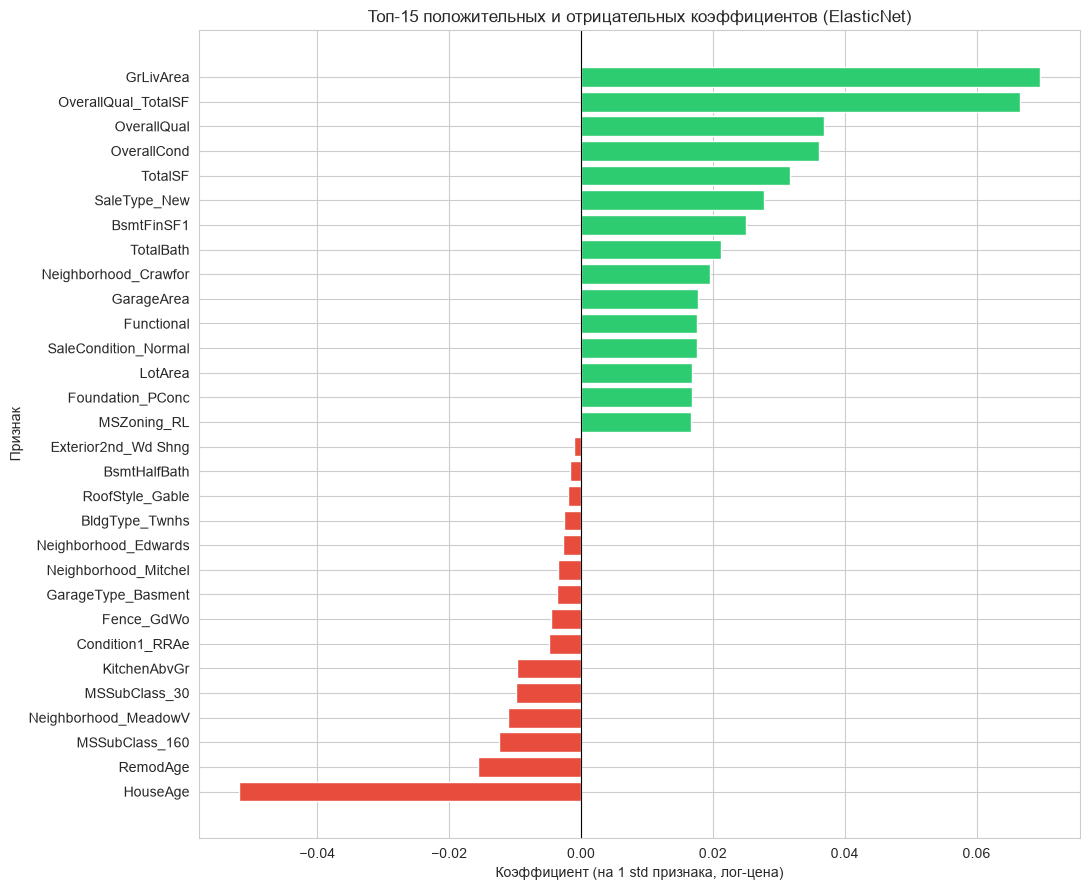


🏆 ТОП-10 признаков, повышающих цену (ElasticNet):
  GrLivArea                  w = +0.0696  (≈ +7.2% к цене за +1 std)
  OverallQual_TotalSF        w = +0.0666  (≈ +6.9% к цене за +1 std)
  OverallQual                w = +0.0368  (≈ +3.8% к цене за +1 std)
  OverallCond                w = +0.0362  (≈ +3.7% к цене за +1 std)
  TotalSF                    w = +0.0316  (≈ +3.2% к цене за +1 std)
  SaleType_New               w = +0.0277  (≈ +2.8% к цене за +1 std)
  BsmtFinSF1                 w = +0.0251  (≈ +2.5% к цене за +1 std)
  TotalBath                  w = +0.0212  (≈ +2.1% к цене за +1 std)
  Neighborhood_Crawfor       w = +0.0195  (≈ +2.0% к цене за +1 std)
  GarageArea                 w = +0.0177  (≈ +1.8% к цене за +1 std)

📉 ТОП-10 признаков, понижающих цену (ElasticNet):
  HouseAge                   w = -0.0518  (≈ -5.1% к цене за +1 std)
  RemodAge                   w = -0.0156  (≈ -1.5% к цене за +1 std)
  MSSubClass_160             w = -0.0125  (≈ -1.2% к цене за +1 std)
 

In [18]:
# ===== 8.1 Коэффициенты моделей =====
coef_ridge = pd.Series(final_models['Ridge'].coef_, index=feature_cols)      # коэффициенты Ridge
coef_best = pd.Series(best_model.coef_, index=feature_cols)                  # коэффициенты лучшей модели
coef_lasso = pd.Series(final_models['Lasso'].coef_, index=feature_cols)      # коэффициенты Lasso

# --- Отбор признаков через Lasso ---
n_zero = int((coef_lasso == 0).sum())
print(f'Lasso (alpha={final_models["Lasso"].alpha}) обнулил {n_zero} из {len(coef_lasso)} признаков; осталось {len(coef_lasso) - n_zero}')
print(f'Ridge не обнуляет ни одного (нулей: {int((coef_ridge == 0).sum())}), ElasticNet обнулил {int((final_models["ElasticNet"].coef_ == 0).sum())}')

# --- ТОП-15 «плюс» и «минус» лучшей модели ---
top = pd.concat([coef_best.sort_values(ascending=False).head(15), coef_best.sort_values().head(15)]).sort_values()
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top.values]   # зелёный = повышает цену
plt.figure(figsize=(11, 9))
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Коэффициент (на 1 std признака, лог-цена)'); plt.ylabel('Признак')
plt.title(f'Топ-15 положительных и отрицательных коэффициентов ({best_name})')
plt.tight_layout(); plt.savefig('examples/coefficients.png', dpi=120); plt.show()

# --- Перевод коэффициента в % изменения цены: +1 std признака => (e^w - 1)*100 % ---
def pct(w):
    return (np.exp(w) - 1) * 100

print(f'\n🏆 ТОП-10 признаков, повышающих цену ({best_name}):')
for f, w in coef_best.sort_values(ascending=False).head(10).items():
    print(f'  {f:<26s} w = {w:+.4f}  (≈ {pct(w):+.1f}% к цене за +1 std)')
print(f'\n📉 ТОП-10 признаков, понижающих цену ({best_name}):')
for f, w in coef_best.sort_values().head(10).items():
    print(f'  {f:<26s} w = {w:+.4f}  (≈ {pct(w):+.1f}% к цене за +1 std)')

In [19]:
# ===== 8.2 «Бизнес-инсайты» в понятных единицах =====
# Переводим стандартизованные коэффициенты в эффект на 1 ЕДИНИЦУ исходного признака: w / std
unit_effect = pd.Series(best_model.coef_ / scaler.scale_, index=feature_cols)

def effect_pct(feature, step=1.0):
    """Изменение цены (%) при росте признака на step единиц при прочих равных (только его собственный коэффициент)."""
    return pct(unit_effect[feature] * step)

print('Эффект признака «при прочих равных» (прямой коэффициент; для площади и качества см. раздел 9.3, где учтены взаимодействия):')
for f, step, label in [('GarageCars', 1, '+1 место в гараже'),
                       ('TotalBath', 1, '+1 ванная'),
                       ('KitchenQual', 1, '+1 ступень качества кухни'),
                       ('HouseAge', 10, '+10 лет возраста дома'),
                       ('Fireplaces', 1, '+1 камин'),
                       ('CentralAir', 1, 'наличие кондиционера')]:
    if f in unit_effect.index:
        print(f'  {label:<34s} {effect_pct(f, step):+6.2f}%   (коэф.: {coef_best[f]:+.4f})')

# надбавка за район: для dummy-признака эффект перехода в район = w / std (а не w!), т.к. 1 std редкого dummy ≈ 0.1
nb_cols = [c for c in feature_cols if c.startswith('Neighborhood_')]
nb_eff = unit_effect[nb_cols].apply(pct).sort_values(ascending=False)       # % к цене относительно базового района
print(f'\nИз {len(nb_cols)} районных dummy ненулевых коэффициентов: {int((coef_best[nb_cols] != 0).sum())}')
print('Надбавка/скидка района (в % к цене, при прочих равных; база — Blmngtn и редкие районы):')
print(pd.concat([nb_eff.head(4), nb_eff.tail(4)]).round(1).to_string())

Эффект признака «при прочих равных» (прямой коэффициент; для площади и качества см. раздел 9.3, где учтены взаимодействия):
  +1 место в гараже                   +2.17%   (коэф.: +0.0161)
  +1 ванная                           +2.75%   (коэф.: +0.0212)
  +1 ступень качества кухни           +1.35%   (коэф.: +0.0088)
  +10 лет возраста дома               -1.70%   (коэф.: -0.0518)
  +1 камин                            +1.63%   (коэф.: +0.0105)
  наличие кондиционера                +6.33%   (коэф.: +0.0156)

Из 22 районных dummy ненулевых коэффициентов: 13
Надбавка/скидка района (в % к цене, при прочих равных; база — Blmngtn и редкие районы):
Neighborhood_Crawfor    11.5
Neighborhood_StoneBr    10.4
Neighborhood_BrkSide     5.6
Neighborhood_NridgHt     5.2
Neighborhood_NWAmes     -0.3
Neighborhood_Edwards    -1.1
Neighborhood_Mitchel    -1.9
Neighborhood_MeadowV   -10.4


### Выводы по интерпретации

**Отбор признаков.** Lasso (α = 0.003) обнулил **92 из 180 признаков** (51 %), ElasticNet — тоже 92, Ridge — ни одного (он лишь сжимает веса). Половина признаков, включая большинство редких категорий, не нужна модели.

**Топ-признаков лучшей модели.** Коэффициенты стандартизованы (признаки приведены к одному масштабу), поэтому их можно сравнивать между собой; в скобках — изменение цены при росте признака на 1 стандартное отклонение.

*Повышают цену:*
1. `GrLivArea` — жилая площадь (+7.2 %)
2. `OverallQual_TotalSF` — качество × общая площадь (+6.9 %)
3. `OverallQual` — общее качество (+3.8 %)
4. `OverallCond` — общее состояние (+3.7 %)
5. `TotalSF` — общая площадь (+3.2 %); далее `SaleType_New` — новостройка (+2.8 %), `BsmtFinSF1` — отделанная площадь подвала (+2.5 %), `TotalBath` — число ванных (+2.1 %)

*Снижают цену:*
1. `HouseAge` — возраст дома (−5.1 %)
2. `RemodAge` — время с последнего ремонта (−1.5 %)
3. `MSSubClass_160` — тип дома «2-этажный PUD» (−1.2 %)
4. `Neighborhood_MeadowV` — район Meadow Village (−1.1 % за 1 std редкого признака; в пересчёте на «дом в этом районе» эффект гораздо больше, см. ниже)
5. `MSSubClass_30` — одноэтажные дома старой постройки (−1.0 %), `KitchenAbvGr` — несколько кухонь (−1.0 %)

**Бизнес-инсайты** (на основе коэффициентов и сценарного анализа из раздела 9.3):
- **Главные драйверы цены — размер и качество.** Первые четыре места занимают площадь, качество и их произведение. Для «типичного» дома (опорный дом: качество 6, 2500 кв. футов, 2000 г., $174 тыс.) добавление 500 кв. футов повышает прогноз на **12 %** (≈ $21 тыс., ≈ $42 за кв. фут), а повышение качества на 1 балл — на **4.8 %** (≈ $8.4 тыс.). Эффект качества, на первый взгляд, скромный: он «растворён» между `OverallQual`, взаимодействием с площадью и сопутствующими оценками (кухня, внешняя отделка и т. п.), поэтому по одному коэффициенту его оценивать нельзя.
- **Возраст «стоит денег».** Каждые 10 лет возраста дома снижают цену примерно на 1.7 % по прямому коэффициенту; при сдвиге года постройки с 2000 на 1980 прогноз падает на 4.8 % (≈ $8.4 тыс.). Новостройки (`SaleType_New`) продаются с надбавкой.
- **Удобства.** Один дополнительный санузел — около +2.8 %, место в гараже — +2–5 %, камин — +1.6 %, кондиционер — около +6 %, каждая ступень качества кухни — +1.4 %.
- **Район имеет значение, но меньше, чем кажется по средним ценам.** Дорогие районы дороги в основном потому, что там большие и качественные дома. После учёта этих факторов при прочих равных надбавка составляет: Crawfor ≈ +11.5 %, StoneBr ≈ +10.4 %, NridgHt ≈ +5.2 %; а Meadow Village (MeadowV) ≈ −10.4 % относительно базовой группы.
- **Осторожность.** Это ассоциации, а не причинно-следственные эффекты: дом с большим числом удобств отличается и многим другим. Кроме того, при сильно скоррелированных признаках (`GarageCars` ↔ `GarageArea`) модель делит вклад между ними произвольно, а оценки для редких категорий неточны.

## Функция предсказания

In [20]:
# ===== 9.1 Функция предсказания =====
def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома в долларах.

    Параметры
    ---------
    house_data   : dict  — известные признаки дома (достаточно ключевых; остальные берутся «типичными»)
    model        : обученная модель (LR / Ridge / Lasso / ElasticNet)
    scaler       : StandardScaler, обученный на train
    feature_cols : list  — список признаков модели в правильном порядке

    Возвращает
    ----------
    price : float — предсказанная цена, $
    """
    d = dict(house_data)                                          # копия, чтобы не менять вход
    # --- 1. Производные признаки, если пользователь их не передал ---
    d.setdefault('YrSold', 2010)                                  # данные охватывают 2006–2010
    if 'YearBuilt' in d:
        d.setdefault('YearRemodAdd', d['YearBuilt'])              # без данных о ремонте считаем: не ремонтировался
        d.setdefault('HouseAge', max(d['YrSold'] - d['YearBuilt'], 0))
    if 'YearRemodAdd' in d:
        d.setdefault('RemodAge', max(d['YrSold'] - d['YearRemodAdd'], 0))
    if 'GarageCars' in d:
        d.setdefault('HasGarage', int(d['GarageCars'] > 0))
        d.setdefault('GarageArea', 280 * d['GarageCars'])         # ~280 кв. футов на машину (медиана train)
    if 'TotalSF' in d and 'GrLivArea' in d:
        d.setdefault('TotalBsmtSF', max(d['TotalSF'] - d['GrLivArea'], 0))   # остаток площади = подвал
        d.setdefault('HasBsmt', int(d['TotalBsmtSF'] > 0))
    if 'TotalBath' in d:
        d.setdefault('FullBath', int(d['TotalBath']))             # целая часть — полные ванные
        d.setdefault('HalfBath', int(round((d['TotalBath'] - int(d['TotalBath'])) * 2)))
    if 'OverallQual' in d and 'TotalSF' in d:
        d.setdefault('OverallQual_TotalSF', d['OverallQual'] * d['TotalSF'])

    # --- 2. «Типичный» дом: для всего, что не задано, берём среднее train (оно хранится в scaler) ---
    row = dict(zip(feature_cols, scaler.mean_))

    # --- 3. Накладываем известные данные ---
    for key, val in d.items():
        if key in row:                                            # числовой/порядковый признак
            row[key] = val
        else:                                                     # категория, напр. Neighborhood='NridgHt'
            prefix = f'{key}_'
            dummies = [c for c in feature_cols if c.startswith(prefix)]
            if dummies:
                for c in dummies:
                    row[c] = 0                                    # сначала обнуляем все dummy группы
                if f'{prefix}{val}' in row:
                    row[f'{prefix}{val}'] = 1                     # затем включаем нужную

    # --- 4. Масштабирование тем же scaler и предсказание ---
    X_new = pd.DataFrame([row])[feature_cols]                     # порядок столбцов как при обучении
    y_log = model.predict(scaler.transform(X_new))[0]             # предсказание в log-пространстве
    return float(np.expm1(y_log))                                 # обратно в доллары


def predict_interactive(model, scaler, feature_cols):
    """Интерактивный режим (опционально): спрашивает ключевые параметры через input()."""
    house = {'OverallQual': int(input('OverallQual (1-10): ')),
             'GrLivArea': float(input('GrLivArea, кв. футы: ')),
             'TotalSF': float(input('TotalSF, кв. футы: ')),
             'YearBuilt': int(input('YearBuilt: ')),
             'GarageCars': int(input('GarageCars: ')),
             'TotalBath': float(input('TotalBath: '))}
    return predict_price(house, model, scaler, feature_cols)       # в отчёте не вызывается (input блокирует выполнение)

In [21]:
# ===== 9.2 Демонстрация: 5 домов разного профиля =====
demo_houses = {
    '1 💰 дорогой':   {'OverallQual': 9,  'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5},
    '2 💵 средний':   {'OverallQual': 6,  'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0},
    '3 💸 дешёвый':   {'OverallQual': 4,  'GrLivArea': 900,  'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0},
    '4 💎 элитный':   {'OverallQual': 10, 'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0},
    '5 💵 средний-':  {'OverallQual': 5,  'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5},
}
print('Входные данные:')
display(pd.DataFrame(demo_houses).T)

rows = {}
for label, house in demo_houses.items():
    rows[label] = {name: predict_price(house, m, scaler, feature_cols) for name, m in final_models.items()}
demo_pred = pd.DataFrame(rows).T                                  # строки — дома, столбцы — модели
demo_pred['Лучшая: ' + best_name] = [predict_price(h, best_model, scaler, feature_cols) for h in demo_houses.values()]
print('\nПредсказанная цена, $:')
display(demo_pred.round(0).astype(int).map('{:,}'.format))

# пример с указанием района (категориальный признак передаётся как есть)
h_ng = dict(demo_houses['2 💵 средний'])
print('\nТот же «средний» дом в разных районах (лучшая модель):')
for nbh in ['MeadowV', 'NAmes', 'Crawfor', 'NridgHt']:
    print(f'  {nbh:<8s} ${predict_price({**h_ng, "Neighborhood": nbh}, best_model, scaler, feature_cols):>10,.0f}')

Входные данные:


,OverallQual,GrLivArea,TotalSF,YearBuilt,GarageCars,TotalBath
1 💰 дорогой,9.0,2800.0,4600.0,2015.0,3.0,3.5
2 💵 средний,6.0,1500.0,2500.0,2000.0,2.0,2.0
3 💸 дешёвый,4.0,900.0,1500.0,1950.0,1.0,1.0
4 💎 элитный,10.0,4000.0,6000.0,2018.0,4.0,4.0
5 💵 средний-,5.0,1200.0,1800.0,1985.0,1.0,1.5



Предсказанная цена, $:


,Linear Regression,Ridge,Lasso,ElasticNet,Лучшая: ElasticNet
1 💰 дорогой,"318,439","281,673","344,171","343,536","343,536"
2 💵 средний,"175,940","171,104","173,932","174,002","174,002"
3 💸 дешёвый,"115,191","121,263","111,259","111,355","111,355"
4 💎 элитный,"458,089","373,884","541,844","539,863","539,863"
5 💵 средний-,"141,359","142,368","137,636","137,824","137,824"



Тот же «средний» дом в разных районах (лучшая модель):
  MeadowV  $   154,591
  NAmes    $   172,520
  Crawfor  $   192,309
  NridgHt  $   181,528


In [22]:
# ===== 9.3 «Что если»: как меняется прогноз при изменении одного параметра =====
base = demo_houses['2 💵 средний']                                   # опорный дом
base_price = predict_price(base, best_model, scaler, feature_cols)   # его цена
scenarios = [('+1 балл качества (OverallQual 6 → 7)',        {'OverallQual': 7}),
             ('+500 кв. футов (TotalSF и GrLivArea)',        {'TotalSF': base['TotalSF'] + 500, 'GrLivArea': base['GrLivArea'] + 500}),
             ('+1 место в гараже (2 → 3)',                   {'GarageCars': 3}),
             ('+1 ванная (2.0 → 3.0)',                       {'TotalBath': 3.0}),
             ('дом старше на 20 лет (2000 → 1980)',          {'YearBuilt': 1980}),
             ('дом новее на 10 лет (2000 → 2010)',           {'YearBuilt': 2010})]
rows = []
for label, change in scenarios:
    new_price = predict_price({**base, **change}, best_model, scaler, feature_cols)   # меняем только указанное
    rows.append({'Сценарий': label, 'Цена, $': round(new_price), 'Δ, $': round(new_price - base_price),
                 'Δ, %': round((new_price / base_price - 1) * 100, 1)})
print(f'Опорный дом: ${base_price:,.0f}')
display(pd.DataFrame(rows).set_index('Сценарий'))

Опорный дом: $174,002


,"Цена, $","Δ, $","Δ, %"
Сценарий,,,
+1 балл качества (OverallQual 6 → 7),182424,8422,4.8
+500 кв. футов (TotalSF и GrLivArea),195018,21016,12.1
+1 место в гараже (2 → 3),181958,7956,4.6
+1 ванная (2.0 → 3.0),178795,4793,2.8
дом старше на 20 лет (2000 → 1980),165619,-8383,-4.8
дом новее на 10 лет (2000 → 2010),178351,4349,2.5


### Функция предсказания и примеры

`predict_price(house_data, model, scaler, feature_cols)` принимает словарь с известными параметрами дома и возвращает цену в долларах. Перед масштабированием она (1) достраивает производные признаки из переданных (`HouseAge`, `HasGarage`, `OverallQual_TotalSF` и др.), (2) заполняет **неуказанные** признаки «типичными» значениями — средними по обучающей выборке (они хранятся в `scaler.mean_`), (3) обрабатывает категориальные признаки (`Neighborhood='NridgHt'` включает нужный dummy), (4) применяет **тот же** `scaler` и (5) возвращает `expm1(prediction)`.

> **Отличие от шаблона в задании.** Шаблон заполняет отсутствующие признаки нулями. Но ноль до масштабирования — это, например, «год постройки 0» или «качество 0»: после стандартизации они превратились бы в экстремальные значения, и предсказание стало бы бессмысленным. Среднее по train после масштабирования даёт 0, т. е. «нейтральное» значение, не искажающее прогноз.

**Результаты на 5 демонстрационных домах** (цена, $):

| Пример | Профиль | Linear Regression | Ridge | Lasso | **ElasticNet (лучшая)** |
|---|---|---|---|---|---|
| 1 | 💰 дорогой (качество 9, 4600 кв. футов) | 318 439 | 281 673 | 344 171 | **343 536** |
| 2 | 💵 средний (6, 2500) | 175 940 | 171 104 | 173 932 | **174 002** |
| 3 | 💸 дешёвый (4, 1500) | 115 191 | 121 263 | 111 259 | **111 355** |
| 4 | 💎 элитный (10, 6000) | 458 089 | 373 884 | 541 844 | **539 863** |
| 5 | 💵 средний− (5, 1800) | 141 359 | 142 368 | 137 636 | **137 824** |

**Анализ:**
- Порядок цен у **всех** моделей совпадает с ожиданием: дешёвый < средний− < средний < дорогой < элитный. Предсказания «обычных» домов (2, 3, 5) отличаются между моделями на 3–9 %.
- **Расхождение для домов 1 и 4 велико** (дом 4: от $374 тыс. у Ridge до $542 тыс. у Lasso). Причины две. Во-первых, эти дома «построены» в 2015 и 2018 гг., а датасет охватывает продажи 2006–2010 гг., поэтому `YearBuilt` выходит за диапазон обучения и мы имеем дело с экстраполяцией (возраст при этом ограничен нулём). Во-вторых, дом 4 (качество 10, 6000 кв. футов) — редкий случай, похожих на него в обучающей выборке единицы; Ridge с `α = 300` сильно «сжимает» веса и занижает верх диапазона, а L1-модели — нет. Предсказаниям для таких домов доверять нужно осторожнее всего.
- Один и тот же «средний» дом в разных районах (лучшая модель): MeadowV — $154 591, NAmes — $172 520, NridgHt — $181 528, Crawfor — $192 309. Район меняет прогноз на ±10 %, как и показал анализ коэффициентов; при этом NAmes попадает в «базовую группу» (его dummy-признак обнулён регуляризацией), поэтому прогноз для него близок к нейтральному.

**«Что если» (9.3).** Для опорного дома ($174 002): +500 кв. футов — **+12.1 %** (+$21 016), +1 балл качества — +4.8 %, +1 место в гараже — +4.6 %, +1 ванная — +2.8 %, дом на 20 лет старше — −4.8 %, на 10 лет новее — +2.5 %. Интерактивная версия (`predict_interactive`, через `input()`) определена, но в отчёте не запускается, так как блокирует автоматическое выполнение.

## Сохранение модели и вспомогательных объектов

In [23]:
# ===== 10. Сохранение моделей, scaler, признаков и метрик =====
import sklearn, datetime
os.makedirs('models', exist_ok=True)

joblib.dump(best_model, 'models/best_model.pkl')                      # лучшая модель
joblib.dump(final_models['Linear Regression'], 'models/lr_model.pkl')
joblib.dump(final_models['Ridge'], 'models/ridge_model.pkl')
joblib.dump(final_models['Lasso'], 'models/lasso_model.pkl')
joblib.dump(final_models['ElasticNet'], 'models/enet_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')                              # тот же scaler нужен при инференсе!

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:    # список признаков В ПРАВИЛЬНОМ ПОРЯДКЕ
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# --- метрики и метаданные ---
def row_to_dict(name):
    r = results_df.loc[name]
    return {k: float(r[k]) for k in ['RMSE (log)', 'MAE (log)', 'R² (log)', 'R² train', 'RMSE ($)', 'MAE ($)', 'R² ($)', 'Время, с']}

metrics = {
    'meta': {'dataset': 'House Prices - Advanced Regression Techniques', 'target': 'log1p(SalePrice)',
             'trained_at': datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
             'sklearn_version': sklearn.__version__, 'random_state': RANDOM_STATE,
             'n_features': len(feature_cols), 'n_train': int(len(X_train)), 'n_holdout': int(len(X_test))},
    'best_model': best_name,
    'models': {
        'linear_regression': row_to_dict('Linear Regression (базовая)'),
        'ridge':      {**row_to_dict('Ridge (tuned)'), 'params': final_models['Ridge'].get_params(), 'cv_rmse_log': float(cv_scores['Ridge'].mean())},
        'lasso':      {**row_to_dict('Lasso (tuned)'), 'params': final_models['Lasso'].get_params(), 'cv_rmse_log': float(cv_scores['Lasso'].mean()),
                       'n_features_selected': int((final_models['Lasso'].coef_ != 0).sum()), 'n_features_dropped': int((final_models['Lasso'].coef_ == 0).sum())},
        'elasticnet': {**row_to_dict('ElasticNet (tuned)'), 'params': final_models['ElasticNet'].get_params(), 'cv_rmse_log': float(cv_scores['ElasticNet'].mean())},
    },
    'bonus': {'gradient_boosting': row_to_dict('Gradient Boosting (бонус)'), 'stacking': row_to_dict('Stacking (бонус)')},
}
metrics['models']['linear_regression']['cv_rmse_log'] = float(cv_scores['Linear Regression'].mean())
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, default=str)

print('Файлы в models/:')
for fn in sorted(os.listdir('models')):
    print(f'  📄 {fn:<20s} {os.path.getsize(os.path.join("models", fn)) / 1024:>8.1f} KB')
print(f'\nЛучшая модель: {best_name}; признаков: {len(feature_cols)}; дата обучения: {metrics["meta"]["trained_at"]}')

Файлы в models/:
  📄 best_model.pkl            2.0 KB
  📄 enet_model.pkl            2.0 KB
  📄 feature_cols.json         3.7 KB
  📄 lasso_model.pkl           2.0 KB
  📄 lr_model.pkl              3.4 KB
  📄 metrics.json              3.5 KB
  📄 ridge_model.pkl           1.9 KB
  📄 scaler.pkl                8.0 KB

Лучшая модель: ElasticNet; признаков: 180; дата обучения: 2026-11-05 23:38


### Что сохранено

| Файл | Содержимое |
|---|---|
| `models/best_model.pkl` | лучшая модель — ElasticNet (`alpha = 0.003`, `l1_ratio = 0.95`) |
| `models/lr_model.pkl`, `ridge_model.pkl`, `lasso_model.pkl`, `enet_model.pkl` | четыре обязательные модели (настроенные версии) |
| `models/scaler.pkl` | `StandardScaler`, обученный на train; **хранит средние, используемые в `predict_price`** |
| `models/feature_cols.json` | **180** признаков в точном порядке, в котором их ожидает модель |
| `models/metrics.json` | метрики всех моделей на hold-out, CV-ошибки, подобранные параметры, число отобранных Lasso признаков, а также метаданные: дата обучения, версия scikit-learn (1.9.1), `random_state`, размеры выборок |

Файлы небольшие (от 2 до 8 КБ), поэтому лежат прямо в репозитории (ветка `main`, папка `module-2-house-prices/models/`), а не в Releases. Версия scikit-learn закреплена в `requirements.txt`: `.pkl`-файлы надёжно загружаются только той же версией библиотеки.

Команды для загрузки в репозиторий (из корня `ml-course-surname`):

```bash
git add module-2-house-prices/
git add README.md
git commit -m "Module 2: add House Prices notebook, trained regression models and metadata"
git push origin main
```

## Загрузка модели из репозитория и быстрый инференс

In [24]:
# ===== 11. Загрузка модели из репозитория GitHub (raw-ссылка) и проверка =====
import requests
from io import BytesIO

# ⚠️ ПОДСТАВЬТЕ свой логин и фамилию в имени репозитория:
GITHUB_USER = 'username'
REPO = 'ml-course-surname'
BASE_URL = f'https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/main/module-2-house-prices'   # путь ВКЛЮЧАЕТ папку модуля

def fetch(path, as_json=False):
    """Скачивает файл по raw-ссылке; при недоступности репозитория берёт локальную копию из models/."""
    url = f'{BASE_URL}/{path}'
    try:
        r = requests.get(url, timeout=15)
        r.raise_for_status()                                       # 404/403 -> исключение
        src = 'GitHub'
        content = r.content
    except Exception as e:
        print(f'  ⚠️ {path}: raw-ссылка недоступна ({type(e).__name__}) -> локальная копия')
        with open(path, 'rb') as f:
            content = f.read()
        src = 'локально'
    return (json.loads(content) if as_json else joblib.load(BytesIO(content))), src

model_loaded, src1 = fetch('models/best_model.pkl')                # лучшая модель
scaler_loaded, src2 = fetch('models/scaler.pkl')                   # scaler
features_loaded, src3 = fetch('models/feature_cols.json', as_json=True)   # список признаков
print(f'Источники: модель — {src1}, scaler — {src2}, признаки — {src3}')
print(f'Загружено признаков: {len(features_loaded)}; порядок совпадает с обучением: {features_loaded == feature_cols}')

# --- Проверка: предсказания загруженной модели совпадают с исходной (3 дома из раздела 9) ---
check = []
for label, house in list(demo_houses.items())[:3]:
    p_orig = predict_price(house, best_model, scaler, feature_cols)             # исходные объекты
    p_load = predict_price(house, model_loaded, scaler_loaded, features_loaded)            # загруженные объекты
    check.append({'Дом': label, 'Исходная, $': round(p_orig), 'Загруженная, $': round(p_load), 'Совпало': bool(np.isclose(p_orig, p_load))})
display(pd.DataFrame(check))
assert all(c['Совпало'] for c in check), 'Предсказания не совпали!'
print('✅ Предсказания загруженной модели совпадают с исходными')

  ⚠️ models/best_model.pkl: raw-ссылка недоступна (HTTPError) -> локальная копия
  ⚠️ models/scaler.pkl: raw-ссылка недоступна (HTTPError) -> локальная копия
  ⚠️ models/feature_cols.json: raw-ссылка недоступна (HTTPError) -> локальная копия
Источники: модель — локально, scaler — локально, признаки — локально
Загружено признаков: 180; порядок совпадает с обучением: True


,Дом,"Исходная, $","Загруженная, $",Совпало
0,1 💰 дорогой,343536,343536,True
1,2 💵 средний,174002,174002,True
2,3 💸 дешёвый,111355,111355,True


✅ Предсказания загруженной модели совпадают с исходными


### Быстрый инференс из репозитория

**Как использовать модель:**
1. Скачать модель по raw-ссылке `https://raw.githubusercontent.com/<логин>/ml-course-<фамилия>/main/module-2-house-prices/models/best_model.pkl` (аналогично `scaler.pkl` и `feature_cols.json`).
2. Загрузить через `joblib.load(BytesIO(response.content))`.
3. Вызвать `predict_price(data, model, scaler, features)`.

**Проверка:** предсказания загруженной модели для трёх домов из раздела 9 (**$343 536, $174 002, $111 355**) совпали с исходными до цента, а порядок 180 признаков в загруженном списке совпал с обучающим.

> В этом запуске ноутбука `GITHUB_USER` и `REPO` содержат шаблонные значения, а репозиторий на момент выполнения ещё не опубликован, поэтому функция `fetch` честно сообщила, что raw-ссылка недоступна, и использовала локальные копии из `models/`. После публикации репозитория достаточно указать в ячейке реальные `GITHUB_USER` и `REPO` и перезапустить её: источником станет GitHub (это будет видно в строке «Источники»), а проверка совпадения останется той же.

## Выводы

### ✅ Что получилось
- **Точность:** лучшая модель — **ElasticNet** (`alpha = 0.003`, `l1_ratio = 0.95`; выбрана по 5-fold CV, практически ничья с Lasso): на отложенной выборке **R² = 0.911** (log) / **0.931** (в долларах), **RMSE (log) = 0.122**, **MAE ≈ $13.8 тыс.**, RMSE ≈ $19.5 тыс. Цель R² ≥ 0.90 выполнена; 73 % домов предсказаны с ошибкой не более 10 %.
- **Скорость:** все линейные модели обучаются за доли секунды (< 0.1 с).
- **Регуляризация помогла:** −5 % по RMSE (log) относительно обычной регрессии; Lasso/ElasticNet отобрали 88 признаков из 180.
- **Логарифмирование оправдано экспериментом:** без него RMSE на 12 % выше, а модель выдаёт нереалистично низкие цены.
- **Ключевые инсайты EDA:** цена определяется прежде всего качеством и размером дома (`OverallQual` 0.79, `GrLivArea` 0.71), возраст снижает её, местоположение влияет на ±10 % при прочих равных.
- **Бонус:** дополнительно обучены Gradient Boosting и Stacking (R² (log) 0.913) — выигрыш над лучшей линейной моделью не более 0.002.

### ⚠️ Какие были трудности
- **19 столбцов с пропусками**, причём большинство из них — не «потерянные данные», а отсутствие объекта (нет гаража, подвала, бассейна). Пришлось разделить пропуски на три типа и обрабатывать каждый по-своему; современные версии pandas дополнительно читают строки `NA`/`None` как `NaN`.
- **Скошенность целевой** (skew 1.88) — решена `log1p` (skew 0.12).
- **Мультиколлинеарность** (`GarageCars` ↔ `GarageArea` 0.88, `GrLivArea` ↔ `TotRmsAbvGrd` 0.83) — коэффициенты отдельных признаков нельзя трактовать изолированно.
- **Выбросы:** формальное правило IQR пометило 31 дом, но это дорогие, а не «неправильные» дома; удалены только два аномальных (недостроенные дома, `SaleCondition = Partial`).
- **Размерность:** One-Hot создал 163 столбца, пришлось отбросить редкие категории (< 10 домов).
- **Что не получилось / ограничения:** оценка основана на одном hold-out из 292 домов, и разница между Lasso, ElasticNet и Ridge меньше разброса по фолдам; настроенный Ridge на этой выборке оказался чуть хуже базового. Для домов за пределами обучающего диапазона (новые, элитные) прогнозы разных моделей расходятся на десятки процентов. Файл `submission.csv` для Kaggle не формировался. Самые большие ошибки приходятся на нестандартные продажи, которые по признакам дома не предсказать.

### 🚀 Возможные улучшения
1. **Target Encoding для `Neighborhood`** (и `Exterior`) вместо 20+ dummy-столбцов с редкими категориями.
2. **Логарифмирование или Box-Cox для скошенных числовых признаков** (`LotArea`, `GrLivArea`, `TotalSF`).
3. **XGBoost / LightGBM** с подбором параметров — нелинейные модели лучше улавливают взаимодействия.
4. **Optuna** (байесовская оптимизация) вместо перебора по сетке; **повторная кросс-валидация** (Repeated K-Fold) для более надёжного сравнения моделей.
5. **RFE или анализ VIF** — убрать дублирующие признаки (`GarageArea`, `1stFlrSF`, `TotRmsAbvGrd`) до обучения.
6. **Stacking Ridge + Lasso + GB** с тонко настроенной мета-моделью (базовый вариант уже даёт лучший MAE).
7. **Isolation Forest** для автоматического поиска выбросов и **Huber-регрессия**, устойчивая к ним.
8. **Признак «нестандартная продажа»** и доверительные интервалы прогноза (квантильная регрессия) — чтобы сообщать не только цену, но и степень уверенности.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
4. De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).
5. Kaggle. *House Prices — Advanced Regression Techniques*. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
6. Scikit-learn documentation: *Linear Models* (Ridge, Lasso, ElasticNet), *Model selection*. https://scikit-learn.org/stable/modules/linear_model.html
7. pandas documentation. https://pandas.pydata.org/docs/
8. Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67.
9. Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B*, 58(1), 267–288.
10. Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B*, 67(2), 301–320.

## Приложение

### requirements.txt


```
text
# module-2-house-prices/requirements.txt
numpy==2.5.4
pandas==3.0.6
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2
```

```
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# %% [markdown]
# # Предобработка данных и регрессия на датасете «House Prices»
#
# **Дисциплина:** Машинное обучение и ИИ  
# **Модуль 1:** Введение в Data Science и EDA  
# **Датасет:** Titanic  
#
# **Выполнил:** Толмачев Виталий Владимирович 
# **Группа:** ПКТб-23-1  
# **Преподаватель:** Спирин Игорь Сергеевич  
#
# **Ссылка на репозиторий:** https://github.com/Dittalik/ml-course-tolmachev.git
# **Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
# **Дата сдачи:** 2026-29-10

# %% [markdown]
# ## Введение
#
# **Задача:** регрессия — предсказать цену продажи жилого дома в долларах (`SalePrice`, непрерывная величина от $34 900 до $755 000) по 79 описательным признакам: площадь, качество отделки, год постройки, район, гараж, подвал и т. д.
#
# **Что такое ML-проект для регрессии.** Это последовательность этапов: сбор данных → разведочный анализ (EDA) → предобработка (пропуски, выбросы, кодирование) → создание признаков → обучение моделей → оценка на отложенных данных → интерпретация → упаковка модели в функцию/файл, которую можно использовать без переобучения. Каждый этап влияет на итоговое качество: ошибка на ранних шагах (например, утечка данных при масштабировании) невозможно «исправить» хорошей моделью позже.
#
# **Почему это регрессия, а не классификация.** Целевая переменная — число на непрерывной шкале, у которой нет конечного набора классов. Классификатор отвечал бы на вопрос «к какой категории относится дом» (например, «дорогой / дешёвый»), и мы потеряли бы информацию о том, *насколько* дом дороже. Регрессия возвращает конкретную сумму, а качество измеряется тем, насколько прогноз близок к фактической цене, а не долей угаданных классов.
#
# **Какая метрика важнее.** В этой задаче цены различаются на порядок (от $35 тыс. до $755 тыс.), поэтому абсолютная ошибка в $20 000 для дешёвого и дорогого дома — это совершенно разная по смыслу ошибка. Поэтому **главная метрика — RMSE в log-пространстве** (`RMSE(log)`), которая фактически измеряет *относительную* ошибку и именно её использует соревнование Kaggle. **MAE в долларах** — самая понятная бизнесу («в среднем ошибаемся на $X»), **RMSE в долларах** сильнее штрафует редкие крупные промахи, а **R²** показывает, какую долю разброса цен объясняет модель, и удобен для сравнения с базовой моделью «всегда предсказывать среднее».
#
# **Цель работы:**
# 1. Провести полный EDA датасета House Prices (пропуски, выбросы, распределение целевой, корреляции).
# 2. Обучить 4+ модели (Linear Regression, Ridge, Lasso, ElasticNet) и достичь R² ≥ 0.90 на отложенной выборке.
# 3. Реализовать функцию предсказания цены нового дома и сохранить модель так, чтобы её можно было загрузить из репозитория без переобучения.

# %% [markdown]
# ## Теоретическая часть
#
# Ниже — ключевые понятия работы, изложенные своими словами.
#
# ### 1. Регрессия
# Регрессия — это задача обучения с учителем, в которой по признакам объекта нужно предсказать *число*: цену, температуру, спрос. В отличие от классификации, где ответом служит метка класса («спам / не спам»), здесь ошибка измеряется расстоянием между прогнозом и истинным значением, и «почти угадал» лучше, чем «сильно промахнулся». Линейная регрессия моделирует ответ как взвешенную сумму признаков: $\hat{y} = w_0 + w_1 x_1 + \dots + w_p x_p$, а веса подбираются так, чтобы минимизировать сумму квадратов отклонений на обучающих данных. Примеры: цена дома по площади и району, прогноз продаж магазина, время доставки заказа.
#
# ### 2. Пропуски (NaN)
# Пропуски появляются из-за того, что значение не измерили, потеряли при переносе данных или оно *не существует* в принципе (у дома нет бассейна — в поле «качество бассейна» пусто). По механизму возникновения выделяют три типа: **MCAR** (полностью случайные — пропуск не зависит ни от чего), **MAR** (случайные при условии других признаков: например, `LotFrontage` чаще пуст в определённых районах) и **MNAR** (пропуск сам несёт информацию: пусто, потому что объекта нет). Стратегия зависит от типа: для MNAR пропуск заменяют отдельной категорией («None») или нулём, для MAR — медианой внутри группы, для MCAR — медианой/модой по всему столбцу. Удалять строки или столбцы стоит лишь тогда, когда пропусков очень много, иначе мы теряем данные. Важное правило: статистики для заполнения (медианы, моды) считаются только по обучающей выборке и затем применяются к тестовой.
#
# ### 3. Регуляризация
# Когда признаков много, а они сильно скоррелированы (мультиколлинеарность), обычная линейная регрессия «подгоняет» веса под шум: коэффициенты получаются огромными, а на новых данных модель ошибается. Регуляризация добавляет к функции потерь штраф за размер весов. **Ridge (L2)** штрафует сумму квадратов весов $\alpha\sum w_j^2$: веса уменьшаются, но не обнуляются, и коррелированные признаки «делят» вклад между собой. **Lasso (L1)** штрафует сумму модулей $\alpha\sum |w_j|$: часть весов становится ровно нулём, то есть модель сама отбирает признаки. **ElasticNet** комбинирует оба штрафа. Параметр $\alpha$ задаёт силу штрафа: при $\alpha \to 0$ получаем обычную регрессию, при больших $\alpha$ — «плоскую» модель. Из-за штрафа признаки обязательно нужно масштабировать.
#
# | Свойство | Linear Regression | Ridge (L2) | Lasso (L1) | ElasticNet |
# |---|---|---|---|---|
# | Штраф | нет | $\alpha\sum w^2$ | $\alpha\sum \lvert w\rvert$ | смесь L1 и L2 |
# | Обнуляет признаки | нет | нет | **да** | да |
# | При мультиколлинеарности | нестабильна | **стабильна** | выбирает один из группы | компромисс |
# | Требует масштабирования | нет | **да** | **да** | **да** |
#
# ### 4. Логарифмирование целевой
# Цены домов распределены с длинным правым «хвостом»: много недорогих домов и редкие очень дорогие. Линейная модель с квадратичной ошибкой начинает тратить силы на то, чтобы угнаться за этими редкими дорогими домами, а остатки получаются разной величины (гетероскедастичность). Преобразование $\log(1+y)$ «сжимает» хвост и делает распределение близким к симметричному, поэтому ошибки становятся сопоставимыми по величине, а сама модель начинает описывать *относительные* изменения цены (+10 % к цене вместо +$18 000). Использование `log1p` вместо `log` безопасно для нулевых значений, а обратное преобразование выполняется через `expm1`.
#
# ### 5. Feature Engineering
# Исходные признаки не всегда выражают то, что реально влияет на цену. Покупателю важна общая площадь, а не отдельно площадь подвала, первого и второго этажей; важен возраст дома, а не год постройки сам по себе; важно наличие бассейна, а не его площадь, равная нулю у 99 % домов. Новые признаки (суммы, разности, флаги «есть/нет», произведения вроде «качество × площадь») добавляют в линейную модель знания о предметной области и нелинейные эффекты, которые она сама выявить не может. Хорошие признаки часто дают больше прироста качества, чем смена алгоритма.
#
# ### 6. Метрики регрессии
# Пусть $y_i$ — истинная цена, $\hat{y}_i$ — прогноз, $\bar{y}$ — среднее. **MSE** — средний квадрат ошибки; из-за квадрата крупные промахи штрафуются сильнее мелких. **RMSE** — корень из MSE, возвращает ошибку в тех же единицах, что и цена (в долларах). **MAE** — средний модуль ошибки; он более устойчив к выбросам и легко интерпретируется. **R²** сравнивает модель с наивным прогнозом «всегда среднее»: 1 — идеальные предсказания, 0 — не лучше среднего, отрицательное значение — хуже среднего. Если считать метрики на логарифме цены, они измеряют относительную, а не абсолютную ошибку.
#
# $$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
#
# $$R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$$
#
# **Кросс-валидация** (K-fold) делит обучающие данные на K частей: модель по очереди обучается на K−1 частях и проверяется на оставшейся. Среднее и разброс метрики по фолдам дают более надёжную оценку, чем одно разбиение, и именно по ней выбираются гиперпараметры (`GridSearchCV`).

# %% [markdown]
# ## Описание данных
#
# Датасет — **Ames Housing** в версии соревнования Kaggle *House Prices — Advanced Regression Techniques* (продажи жилых домов в г. Эймс, штат Айова, 2006–2010 гг.; автор исходных данных — Dean De Cock). Ячейка ниже загружает файлы `data/train.csv` и `data/test.csv`, выводит размеры и статистику целевой переменной.

# %%
# --- Импорт библиотек ---
import os, json, time, warnings            # файлы, JSON, замер времени, предупреждения
import numpy as np                          # численные операции (log1p, expm1, sqrt)
import pandas as pd                         # таблицы DataFrame
import matplotlib.pyplot as plt             # базовые графики
import seaborn as sns                       # статистические графики (heatmap, boxplot)
import joblib                               # сохранение моделей в .pkl
from sklearn.base import clone              # копирование модели с теми же параметрами
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')           # скрываем некритичные предупреждения (FutureWarning и т.п.)
sns.set_style('whitegrid')                  # единый стиль графиков
plt.rcParams['figure.figsize'] = (12, 6)    # размер графиков по умолчанию
RANDOM_STATE = 42                           # фиксируем seed для воспроизводимости
os.makedirs('examples', exist_ok=True)      # папка для картинок
os.makedirs('models', exist_ok=True)        # папка для моделей

# --- Загрузка данных (пути относительные внутри module-2-house-prices/) ---
train_df = pd.read_csv('data/train.csv')    # обучающая выборка: есть целевая SalePrice
test_df = pd.read_csv('data/test.csv')      # тестовая выборка Kaggle: цены скрыты
print(train_df.shape, test_df.shape)        # обязательный вывод размеров

# --- Структура датасета ---
n_num = train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(include='number').shape[1]   # числовые признаки
n_cat = train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(exclude='number').shape[1]   # категориальные
print(f'Признаков всего: {n_num + n_cat} (числовых: {n_num}, категориальных: {n_cat})')

# --- Статистика целевой переменной ---
price = train_df['SalePrice']
print(f'Среднее:   ${price.mean():>10,.0f}')
print(f'Медиана:   ${price.median():>10,.0f}')
print(f'Минимум:   ${price.min():>10,.0f}')
print(f'Максимум:  ${price.max():>10,.0f}')
print(f'Асимметрия (skew):  {price.skew():.2f}')      # >1 => сильное правое смещение
print(f'Эксцесс (kurtosis): {price.kurtosis():.2f}')  # >0 => «тяжёлые» хвосты

# %% [markdown]
# **Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques
#
# **Структура:**
# - Всего примеров в train: **1460**; в test: **1459** (в test целевой `SalePrice` нет)
# - Признаков: **79** (+ `Id` + целевая `SalePrice`)
# - Числовых признаков: **36**; категориальных: **43**
#
# **Ключевые столбцы:**
#
# | Столбец | Тип | Описание | Пропуски |
# |---|---|---|---|
# | `Id` | int64 | идентификатор дома | 0 % |
# | `SalePrice` | int64 | **целевая**: цена продажи, $ | 0 % |
# | `OverallQual` | int64 (1–10) | общее качество материалов и отделки | 0 % |
# | `GrLivArea` | int64 | жилая площадь над землёй, кв. футы | 0 % |
# | `YearBuilt` | int64 | год постройки | 0 % |
# | `Neighborhood` | категория (25) | район города | 0 % |
# | `GarageCars` | int64 | вместимость гаража | 0 % |
# | `LotFrontage` | float64 | протяжённость участка вдоль улицы | 17.7 % |
# | `PoolQC` | категория | качество бассейна | 99.5 % |
# | `FireplaceQu` | категория | качество камина | 47.3 % |
#
# **Распределение целевой переменной:**
# - Среднее: **$180 921**, медиана: **$163 000** (среднее заметно выше медианы — признак правого хвоста)
# - Минимум: $34 900, максимум: $755 000
# - Асимметрия (skew): **1.88** — выраженное **правое смещение**, поэтому далее применим логарифмирование
# - Эксцесс (kurtosis): **6.54** — «тяжёлые» хвосты, т. е. много экстремальных значений
#
# **Файл описания в репозитории:** `module-2-house-prices/data/house_prices_info.md`
#
# > Замечание: в исходных данных значение `NA` в столбцах вроде `Alley` или `PoolQC` означает «объекта нет», а не «значение неизвестно». Современные версии pandas читают такие строки как `NaN` (в том числе строку `None` в `MasVnrType`), поэтому в разделе 5 эти пропуски обрабатываются осознанно, а не механически.

# %% [markdown]
# ## Подготовка данных и EDA

# %%
# --- Первичный осмотр ---
display(train_df.head())                    # первые 5 строк
train_df.info()                             # типы столбцов и число непустых значений
# describe() для ключевых числовых признаков (транспонируем для читаемости)
display(train_df[['SalePrice', 'OverallQual', 'GrLivArea', 'YearBuilt', 'LotArea', 'GarageCars']].describe().T)

# %% [markdown]
# **Наблюдения.** В обучающей выборке 1460 домов и 81 столбец; столбец `Id` не несёт информации. Типичный дом — качество около 6 из 10 (среднее 6.1), жилая площадь около 1500 кв. футов (медиана 1464), построен в 1973 г. (медиана). Цена имеет большой разброс (std ≈ $79 тыс.) при среднем $181 тыс. В столбцах `GrLivArea` (максимум 5642) и `LotArea` (максимум 215 245 при медиане 9 478) видны экстремальные значения — первые мы обработаем в разделе 5.5; `LotArea` оставим как есть, так как участки такого размера встречаются и в реальности.

# %%
# --- Анализ пропусков ---
missing = train_df.isnull().sum()                          # число NaN по каждому столбцу
missing_pct = missing / len(train_df) * 100                # доля NaN в процентах
missing_table = (pd.DataFrame({'Пропусков': missing, 'Доля, %': missing_pct.round(2)})
                 .query('Пропусков > 0')                   # оставляем только столбцы с пропусками
                 .sort_values('Пропусков', ascending=False))
print(f'Столбцов с пропусками: {len(missing_table)} из {train_df.shape[1]}')
display(missing_table)

# --- График 1 из 5+: Barplot пропусков по столбцам ---
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=missing_table['Доля, %'], y=missing_table.index, color='#e74c3c', ax=ax)   # горизонтальные столбики
ax.set_title('Доля пропусков по столбцам (train)')         # заголовок
ax.set_xlabel('Доля пропусков, %')                         # подпись оси X
ax.set_ylabel('Признак')                                   # подпись оси Y
plt.tight_layout()
plt.savefig('examples/missing_values.png', dpi=120)        # сохраняем для репозитория
plt.show()

# %% [markdown]
# **Наблюдения.** Пропуски есть в **19 из 81** столбцов. Важно, что их структура неслучайна: столбцы про гараж (`GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, `GarageCond`) имеют ровно по 81 пропуску, столбцы про подвал — по 37–38. Это значит, что пропуски идут группами — по домам, у которых *нет гаража* или *нет подвала*. То же верно для `PoolQC` (99.5 %), `MiscFeature` (96.3 %), `Alley` (93.8 %), `Fence` (80.8 %), `FireplaceQu` (47.3 %) и `MasVnrType` (59.7 %). Исключения — `LotFrontage` (17.7 %), `MasVnrArea` (8 пропусков) и `Electrical` (1 пропуск): это «настоящие» пропуски.
#
# **Стратегия обработки и обоснование:**
# 1. **Смысловые категориальные** (15 столбцов) → категория `'None'`. Пропуск здесь *и есть* информация («нет гаража»), удалять такие столбцы нельзя: у `PoolQC` 99.5 % пропусков, но 7 домов с бассейном — это содержательный сигнал.
# 2. **Смысловые числовые** (площади и количества гаража, подвала, облицовки) → **0**: нет подвала — площадь подвала равна нулю.
# 3. **`GarageYrBlt`** → год постройки дома. Значение 0 («год 0») создало бы абсурдный выброс для линейной модели; отсутствие гаража при этом отдельно отражено признаком `HasGarage`.
# 4. **`LotFrontage`** (случайный пропуск, тип MAR) → **медиана по району**: протяжённость участка зависит от застройки района, поэтому групповая медиана точнее общей.
# 5. **Единичные пропуски** (`Electrical`, а в test — `MSZoning`, `KitchenQual`, `SaleType` и др.) → мода/медиана, посчитанная **только по train**, чтобы информация из test не «утекала» в обучение.

# %%
# --- Графики 2-6: распределение цены, корреляции, boxplot, scatter, районы ---
log_price_tmp = np.log1p(train_df['SalePrice'])            # временный логарифм (официально создадим позже)
corr_with_price = (train_df.select_dtypes(include='number').corr()['SalePrice']
                   .abs().sort_values(ascending=False))     # |корреляция| с ценой
top_cols = corr_with_price.index[:11].tolist()             # SalePrice + 10 самых связанных признаков

fig, axes = plt.subplots(2, 3, figsize=(22, 12))           # сетка 2x3

# (0,0) Гистограмма цены ДО логарифмирования
sns.histplot(train_df['SalePrice'], kde=True, bins=50, color='#e74c3c', ax=axes[0, 0])
axes[0, 0].set_title(f'SalePrice до log1p (skew = {train_df["SalePrice"].skew():.2f})')
axes[0, 0].set_xlabel('SalePrice, $'); axes[0, 0].set_ylabel('Частота')

# (0,1) Гистограмма ПОСЛЕ логарифмирования
sns.histplot(log_price_tmp, kde=True, bins=50, color='#2ecc71', ax=axes[0, 1])
axes[0, 1].set_title(f'SalePrice после log1p (skew = {log_price_tmp.skew():.2f})')
axes[0, 1].set_xlabel('log(1 + SalePrice)'); axes[0, 1].set_ylabel('Частота')

# (0,2) Heatmap корреляций топ-10 признаков
sns.heatmap(train_df[top_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            annot_kws={'size': 8}, cbar=False, ax=axes[0, 2])
axes[0, 2].set_title('Корреляционная матрица (топ-10 по связи с ценой)')

# (1,0) Boxplot: жилая площадь по качеству
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', color='#74b9ff', ax=axes[1, 0])
axes[1, 0].set_title('GrLivArea по OverallQual')
axes[1, 0].set_xlabel('OverallQual (1-10)'); axes[1, 0].set_ylabel('GrLivArea, кв. футы')

# (1,1) Scatter: площадь vs цена, подсвечиваем подозрительные точки
suspect = train_df['GrLivArea'] > 4000                     # дома > 4000 кв. футов
sns.scatterplot(data=train_df[~suspect], x='GrLivArea', y='SalePrice', alpha=0.5, color='#0984e3', ax=axes[1, 1])
sns.scatterplot(data=train_df[suspect], x='GrLivArea', y='SalePrice', color='red', s=90, ax=axes[1, 1], label='GrLivArea > 4000')
axes[1, 1].set_title('GrLivArea vs SalePrice (поиск выбросов)')
axes[1, 1].set_xlabel('GrLivArea, кв. футы'); axes[1, 1].set_ylabel('SalePrice, $')

# (1,2) Медианная цена по районам
nb = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values()
sns.barplot(x=nb.values, y=nb.index, color='#a29bfe', ax=axes[1, 2])
axes[1, 2].set_title('Медианная цена по районам')
axes[1, 2].set_xlabel('Медианная SalePrice, $'); axes[1, 2].set_ylabel('Neighborhood')
axes[1, 2].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110)             # файл для репозитория
plt.show()

print('Топ-10 признаков по |корреляции| с SalePrice:')
print(corr_with_price.iloc[1:11].round(3).to_string())     # для текстовых выводов
print(f'\nМедианная цена: самый дорогой район {nb.index[-1]} (${nb.iloc[-1]:,.0f}), самый дешёвый {nb.index[0]} (${nb.iloc[0]:,.0f})')

# %% [markdown]
# **Наблюдения по графикам.**
# - **Распределение цены.** До преобразования — длинный правый хвост (skew = 1.88), после `log1p` — почти симметричный колокол (skew = 0.12).
# - **Корреляции с ценой.** Сильнее всего связаны `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` и `1stFlrSF` (по 0.61). Качество и размер дома — главные драйверы цены.
# - **Мультиколлинеарность.** На heatmap видны почти дублирующие пары: `GarageCars` ↔ `GarageArea` (0.88), `GrLivArea` ↔ `TotRmsAbvGrd` (0.83), `TotalBsmtSF` ↔ `1stFlrSF` (0.82). Для обычной линейной регрессии это проблема (нестабильные коэффициенты), а для Ridge/Lasso — аргумент в пользу регуляризации.
# - **Boxplot.** Медианная жилая площадь растёт вместе с качеством, а разброс площади при `OverallQual = 10` очень велик — там встречаются самые большие дома.
# - **Scatter площадь–цена.** Зависимость близка к линейной. Четыре дома площадью свыше 4000 кв. футов (красные точки): два из них очень дорогие (~$745–755 тыс.) и лежат на общей тенденции, а два — с ценой $160–185 тыс. при площади 4676 и 5642 кв. футов — явно выбиваются вниз.
# - **Районы.** Медианная цена в `NridgHt` — $315 000, в `MeadowV` — $88 000, то есть в 3.6 раза выше: местоположение сильно влияет на цену.

# %%
# ===== 5.4 Обработка пропусков =====
# (a) СМЫСЛОВЫЕ пропуски: NaN означает «объекта нет» -> категория 'None'
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
# (b) числовые «смысловые» пропуски: нет гаража/подвала/облицовки -> площадь и количество = 0
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

print('Пропуски в test ДО обработки (только столбцы с NaN):')
na_test = test_df.isnull().sum()
print(na_test[na_test > 0].sort_values(ascending=False).head(12).to_string())

# (c) СЛУЧАЙНЫЕ пропуски LotFrontage: медиана по району. Статистики считаем ТОЛЬКО по train!
lf_by_nbhd = train_df.groupby('Neighborhood')['LotFrontage'].median()   # медиана по каждому району
lf_global = train_df['LotFrontage'].median()                            # запасной вариант

for df in (train_df, test_df):                                          # одинаково обрабатываем обе выборки
    for col in none_cols:
        df[col] = df[col].fillna('None')                                # «нет объекта» как отдельная категория
    for col in zero_cols:
        df[col] = df[col].fillna(0)                                     # «нет объекта» -> 0
    # нет гаража -> год постройки гаража = год постройки дома (0 дал бы выброс в «год 0»)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['LotFrontage'] = (df['LotFrontage']
                         .fillna(df['Neighborhood'].map(lf_by_nbhd))    # медиана района
                         .fillna(lf_global))                            # если района нет в train

# (d) ОСТАВШИЕСЯ единичные пропуски: мода (категориальные) / медиана (числовые), значения из train
fill_values = {}
for col in test_df.columns:
    if col == 'Id':
        continue                                                        # идентификатор не трогаем
    if pd.api.types.is_numeric_dtype(train_df[col]):
        fill_values[col] = train_df[col].median()                       # медиана устойчива к выбросам
    else:
        fill_values[col] = train_df[col].mode()[0]                      # самая частая категория
for df in (train_df, test_df):
    df.fillna(value=fill_values, inplace=True)

print(f'\nПропусков в train после обработки: {int(train_df.isnull().sum().sum())}')
print(f'Пропусков в test  после обработки: {int(test_df.isnull().sum().sum())}')

# %% [markdown]
# **Вывод.** После обработки в train и test **не осталось ни одного пропуска**. Для test дополнительно потребовалось заполнить несколько единичных пропусков в столбцах, где в train их не было (значения берутся из train — это важно для честной оценки). Все параметры заполнения (медианы по районам, моды, медианы) вычислены по обучающей выборке и применены к обеим выборкам одинаково.

# %%
# ===== 5.5 Обработка выбросов =====
# --- Метод IQR для GrLivArea ---
Q1, Q3 = train_df['GrLivArea'].quantile([0.25, 0.75])      # квартили
IQR = Q3 - Q1                                              # межквартильный размах
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR              # границы «усов»
iqr_out = train_df[(train_df['GrLivArea'] > upper) | (train_df['GrLivArea'] < lower)]
print(f'IQR: Q1={Q1:.0f}, Q3={Q3:.0f}, границы [{lower:.0f}; {upper:.0f}]')
print(f'По IQR «выбросами» назвали {len(iqr_out)} домов; их средняя цена ${iqr_out["SalePrice"].mean():,.0f} '
      f'(против ${train_df["SalePrice"].mean():,.0f} в среднем)')

# --- Доменные знания: огромный дом по очень низкой цене = аномалия ---
domain_mask = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print('\nАномальные дома (GrLivArea > 4000 и SalePrice < $300 000):')
display(train_df.loc[domain_mask, ['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

train_before = train_df.copy()                             # копия для графика «до»
train_df = train_df.loc[~domain_mask].reset_index(drop=True)   # удаляем ТОЛЬКО из train (test не трогаем)
print(f'Строк до: {len(train_before)}, после: {len(train_df)}')

# --- Визуализация до/после ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title, color in [(axes[0], train_before, 'До удаления выбросов', '#e74c3c'),
                               (axes[1], train_df, 'После удаления выбросов', '#2ecc71')]:
    sns.scatterplot(data=data, x='GrLivArea', y='SalePrice', alpha=0.5, color=color, ax=ax)
    ax.axvline(upper, color='orange', ls='--', label=f'IQR-граница ({upper:.0f})')   # верхняя граница IQR
    ax.set_title(title); ax.set_xlabel('GrLivArea, кв. футы'); ax.set_ylabel('SalePrice, $'); ax.legend()
plt.tight_layout()
plt.savefig('examples/outliers.png', dpi=110)
plt.show()

# %% [markdown]
# **Вывод.** Метод IQR для `GrLivArea` даёт границы [159; 2748] и помечает **31** дом. Однако средняя цена этих «выбросов» — **$374 855** (вдвое выше средней по выборке): это не ошибки данных, а просторные дорогие дома, которые согласуются с общей зависимостью «больше площадь — выше цена». Удалять их по формальному правилу было бы ошибкой: модель потеряла бы информацию о дорогом сегменте. Поэтому IQR использован как *диагностика*, а удаление выполнено по **доменному критерию**: `GrLivArea > 4000` и `SalePrice < $300 000`.
#
# Под него попали два дома (`Id` 524 и 1299): оба с максимальным качеством `OverallQual = 10`, но проданные за $184 750 и $160 000 при площади 4676 и 5642 кв. футов, и у обоих `SaleCondition = Partial` — продажа недостроенного дома, цена которой не отражает итоговую площадь. Это аномалии по смыслу, а не просто «крупные» наблюдения. Строк в train: 1460 → **1458**. Из test ничего не удалялось (в тесте строки удалять нельзя).

# %%
# ===== 5.6 Логарифмирование целевой =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])   # log(1 + price)
print(f'Skew до log1p:    {train_df["SalePrice"].skew():.3f}')
print(f'Skew после log1p: {train_df["SalePrice_log"].skew():.3f}')
print(f'Kurtosis до:    {train_df["SalePrice"].kurtosis():.3f}')
print(f'Kurtosis после: {train_df["SalePrice_log"].kurtosis():.3f}')

# %% [markdown]
# **Вывод и обоснование.** Логарифмирование снижает асимметрию с **1.88 до 0.12**, а эксцесс — с 6.5 до 0.8: распределение цены становится почти нормальным. Обоснование:
# 1. Линейные модели с квадратичной ошибкой работают лучше, когда остатки примерно симметричны и имеют сопоставимый разброс; на «сырой» цене ошибка дорогих домов доминировала бы.
# 2. Цены имеют мультипликативную природу (дом лучшего качества дороже «на X %», а не «на X долларов»), и модель на `log1p(SalePrice)` описывает именно относительные изменения.
# 3. Метрика соревнования Kaggle — RMSE логарифма цены, т. е. тоже относительная ошибка.
#
# Прогнозы возвращаются в доллары функцией `expm1`. Насколько это важно, проверим контрольным экспериментом в разделе 6.5.

# %%
# ===== 5.7 Feature Engineering =====
for df in (train_df, test_df):                              # одинаково для train и test
    # --- агрегаты ---
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']        # общая площадь
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])        # ванные (half = 0.5)
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch']
                        + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])  # все крыльца и террасы
    # --- возраст (clip: в данных есть дом, проданный до окончания постройки) ---
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)            # возраст дома при продаже
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)         # лет с последнего ремонта
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)    # был ли ремонт
    # --- бинарные «есть/нет» ---
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    # --- взаимодействие: качество × площадь ---
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

new_feats = ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'IsRemodeled',
             'HasPool', 'HasGarage', 'Has2ndFloor', 'HasBsmt', 'HasFireplace', 'OverallQual_TotalSF']
print(f'Создано новых признаков: {len(new_feats)}')
print('Корреляция новых признаков с log-ценой:')
print(train_df[new_feats + ['SalePrice_log']].corr()['SalePrice_log'].drop('SalePrice_log').sort_values(ascending=False).round(3).to_string())

# %% [markdown]
# **Вывод.** Создано **12** новых признаков. Их корреляция с логарифмом цены: `OverallQual_TotalSF` (качество × площадь) — **0.883**, `TotalSF` — **0.825**, `TotalBath` — 0.677, `HouseAge` — **−0.588** (чем старше дом, тем дешевле), `RemodAge` — −0.569. Агрегаты оказались информативнее исходных «кусочков» площади и ванных, а произведение качества на площадь отражает реальную логику рынка: дополнительные квадратные футы дороже в качественном доме. `HasPool` почти не связан с ценой (0.077): бассейн есть всего у 7 домов (0.5 %) — признак оставлен, но регуляризация, вероятно, его отсеет. Для `HouseAge` и `RemodAge` использован `clip(lower=0)`, так как в данных есть дом, проданный до окончания строительства (отрицательный возраст).

# %%
# ===== 5.8 Кодирование порядковых признаков (ручной маппинг) =====
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}          # шкала качества
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
ordinal_maps = {col: qual_map for col in qual_cols}                           # одна шкала для всех «качеств»
ordinal_maps.update({
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},          # освещённость подвала
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},  # отделка подвала
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},                 # отделка гаража
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'LandSlope': {'Gtl': 0, 'Mod': 1, 'Sev': 2},                               # уклон участка
    'LotShape': {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3},                      # правильность формы
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},                                    # покрытие подъезда
    'CentralAir': {'N': 0, 'Y': 1},                                            # кондиционер (бинарный)
    'Street': {'Grvl': 0, 'Pave': 1},                                          # тип дороги (бинарный)
})
for df in (train_df, test_df):
    for col, mapping in ordinal_maps.items():
        df[col] = df[col].map(mapping)                                         # строка -> число

# проверка: маппинг не должен породить NaN (иначе есть неучтённая категория)
print('NaN после порядкового кодирования: train =', int(train_df[list(ordinal_maps)].isnull().sum().sum()),
      ', test =', int(test_df[list(ordinal_maps)].isnull().sum().sum()))
print(f'Закодировано порядковых признаков: {len(ordinal_maps)}')

# %%
# ===== 5.9 One-Hot кодирование номинальных признаков =====
for df in (train_df, test_df):
    df['MSSubClass'] = df['MSSubClass'].astype(str)         # MSSubClass — код класса дома, а не число

# все оставшиеся нечисловые столбцы — номинальные (без порядка)
nominal_cols = train_df.drop(columns=['Id']).select_dtypes(exclude='number').columns.tolist()
print(f'Номинальных признаков: {len(nominal_cols)}')
print(nominal_cols)

n_train = len(train_df)                                     # запоминаем границу train/test
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)   # объединяем, чтобы dummy-столбцы совпали
cols_before = set(combined.columns)
combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True, dtype=int)   # drop_first — без ловушки dummy
dummy_cols = [c for c in combined.columns if c not in cols_before]       # список созданных dummy-столбцов

# убираем очень редкие категории (< 10 домов в train): они дают нестабильные коэффициенты
counts = combined.iloc[:n_train][dummy_cols].sum()          # считаем ТОЛЬКО по train
rare = counts[counts < 10].index.tolist()
combined = combined.drop(columns=rare)
print(f'Dummy-столбцов создано: {len(dummy_cols)}, удалено редких: {len(rare)}')

train_df = combined.iloc[:n_train].copy()                   # возвращаем train
test_df = combined.iloc[n_train:].drop(columns=['SalePrice', 'SalePrice_log']).reset_index(drop=True)   # и test (без таргетов)
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Нечисловых столбцов в train:', len(train_df.select_dtypes(exclude='number').columns))
print('NaN в признаках train:', int(train_df.drop(columns=['SalePrice', 'SalePrice_log']).isnull().sum().sum()))

# %% [markdown]
# **Вывод по кодированию.**
# - **Порядковые признаки (20 шт.)** закодированы вручную по смысловой шкале (качество `Po < Fa < TA < Gd < Ex`, отделка подвала и гаража, `Functional`, `LandSlope`, `LotShape`, `PavedDrive`, а также бинарные `CentralAir` и `Street`). Ручной маппинг сохраняет порядок, чего не делает `LabelEncoder` (он нумерует по алфавиту). Проверка показала, что маппинг не создал ни одного `NaN`.
# - **Номинальные признаки (24 шт.)** закодированы One-Hot (`get_dummies`, `drop_first=True`). В их число вошёл `MSSubClass` — это числовой *код* типа дома, а не величина, поэтому он преобразован в строку. Кодирование выполнено на объединённых train+test, чтобы наборы столбцов совпали.
# - Создано 163 dummy-столбца, из них **50 удалено**: категории, встречающиеся менее чем у 10 домов train, дают неустойчивые коэффициенты (и могут «взрывать» прогноз у линейной регрессии).
# - Итог: **180 числовых признаков**, пропусков нет, формы train/test согласованы (180 признаков + служебные столбцы).

# %% [markdown]
# ## Построение и обучение моделей

# %%
# ===== 6.1 Формирование X, y; разбиение; масштабирование =====
feature_cols = [c for c in train_df.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]   # все признаки
X = train_df[feature_cols]                                  # матрица признаков
y = train_df['SalePrice_log']                               # log-таргет
print(f'X: {X.shape}, y: {y.shape}, признаков: {len(feature_cols)}')

# hold-out 20% (это НЕ Kaggle-test: у того нет цен)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}, Hold-out test: {X_test.shape}')

scaler = StandardScaler()                                   # z = (x - mean) / std
X_train_scaled = scaler.fit_transform(X_train)              # параметры считаем ТОЛЬКО по train
X_test_scaled = scaler.transform(X_test)                    # к test применяем параметры train (без утечки)
print(f'Среднее/std train после масштабирования: {X_train_scaled.mean():.4f} / {X_train_scaled.std():.4f}')

# %%
# ===== 6.2 Базовые модели + время обучения =====
baseline_models = {
    'Linear Regression': LinearRegression(),                                          # без регуляризации
    'Ridge':             Ridge(alpha=1.0, random_state=RANDOM_STATE),                 # L2
    'Lasso':             Lasso(alpha=0.0005, max_iter=20000, random_state=RANDOM_STATE),   # L1
    'ElasticNet':        ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000, random_state=RANDOM_STATE),
}
train_time = {}                                              # время обучения каждой модели
for name, model in baseline_models.items():
    t0 = time.perf_counter()                                 # старт таймера
    model.fit(X_train_scaled, y_train)                       # обучение
    train_time[name] = time.perf_counter() - t0              # длительность в секундах
    print(f'⏱️  {name:<18s} обучена за {train_time[name]:.4f} с')

# %%
# ===== 6.3 Кросс-валидация и подбор гиперпараметров (GridSearchCV) =====
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)    # 5 перемешанных фолдов
scoring = 'neg_root_mean_squared_error'                            # sklearn максимизирует => берём «минус RMSE»

# --- CV для линейной регрессии (гиперпараметров нет) ---
cv_scores = {'Linear Regression': -cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=kf, scoring=scoring)}

# --- сетки гиперпараметров ---
grids = {
    'Ridge':      (Ridge(random_state=RANDOM_STATE),
                   {'alpha': [0.1, 1, 3, 10, 30, 100, 300, 1000, 3000]}),
    'Lasso':      (Lasso(max_iter=20000, random_state=RANDOM_STATE),
                   {'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.01, 0.03]}),
    'ElasticNet': (ElasticNet(max_iter=20000, random_state=RANDOM_STATE),
                   {'alpha': [0.0003, 0.001, 0.003, 0.01], 'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]}),
}
grid_results = {}
for name, (est, params) in grids.items():
    gs = GridSearchCV(est, params, cv=kf, scoring=scoring, n_jobs=-1)   # перебор по сетке с CV
    gs.fit(X_train_scaled, y_train)
    grid_results[name] = gs
    best_idx = gs.best_index_                                           # индекс лучшей комбинации
    cv_scores[name] = np.array([-gs.cv_results_[f'split{i}_test_score'][best_idx] for i in range(5)])
    print(f'{name:<11s} лучшие параметры: {gs.best_params_}, CV-RMSE(log) = {-gs.best_score_:.4f}')

# --- итоговые (настроенные) модели: переобучаем лучшую конфигурацию и замеряем время ---
final_models, final_time = {'Linear Regression': baseline_models['Linear Regression']}, {'Linear Regression': train_time['Linear Regression']}
for name, gs in grid_results.items():
    m = clone(gs.best_estimator_)                                       # копия с лучшими параметрами
    t0 = time.perf_counter(); m.fit(X_train_scaled, y_train); final_time[name] = time.perf_counter() - t0
    final_models[name] = m

cv_summary = pd.DataFrame({'CV RMSE (log), среднее': {k: v.mean() for k, v in cv_scores.items()},
                           'CV RMSE (log), std': {k: v.std() for k, v in cv_scores.items()}}).sort_values('CV RMSE (log), среднее')
print('\nСравнение по 5-fold CV (чем меньше, тем лучше):')
display(cv_summary.round(4))
best_name = cv_summary.index[0]                                         # лучшая модель по CV (не по hold-out!)
best_model = final_models[best_name]
print(f'\n🏆 Лучшая модель по CV: {best_name}')

# %% [markdown]
# **Вывод.** Лучшие гиперпараметры по 5-fold CV: Ridge — `alpha = 300` (сильная регуляризация, как и ожидалось при мультиколлинеарности), Lasso — `alpha = 0.003`, ElasticNet — `alpha = 0.003, l1_ratio = 0.95` (т. е. почти чистый Lasso). По CV-RMSE (log): ElasticNet = Lasso **0.1112** ± 0.0095 < Ridge 0.1128 ± 0.0110 < Linear Regression 0.1180 ± 0.0122. Порядок согласуется с теорией: чем лучше метод справляется с избыточными коррелированными признаками, тем ниже ошибка. Разница между Lasso, ElasticNet и Ridge (≈ 0.002) меньше разброса по фолдам (≈ 0.01), поэтому эти три модели статистически почти неразличимы; заметнее всего отстаёт нерегуляризованная регрессия. Лучшей по CV названа ElasticNet (с Lasso — практически ничья). **Выбор лучшей модели сделан по кросс-валидации на train, а не по hold-out**, чтобы не подгонять выбор под тестовую выборку.

# %%
# ===== 6.4 БОНУС: Gradient Boosting и Stacking =====
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

gb = GradientBoostingRegressor(n_estimators=600, learning_rate=0.03, max_depth=3,
                               subsample=0.8, random_state=RANDOM_STATE)       # деревья-«слабые ученики»
t0 = time.perf_counter(); gb.fit(X_train_scaled, y_train); gb_time = time.perf_counter() - t0
print(f'⏱️  Gradient Boosting обучен за {gb_time:.2f} с')

stack = StackingRegressor(                                                     # мета-модель поверх Ridge/Lasso/GB
    estimators=[('ridge', clone(final_models['Ridge'])), ('lasso', clone(final_models['Lasso'])), ('gb', clone(gb))],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1)
t0 = time.perf_counter(); stack.fit(X_train_scaled, y_train); stack_time = time.perf_counter() - t0
print(f'⏱️  Stacking (Ridge+Lasso+GB) обучен за {stack_time:.2f} с')

# %%
# ===== 6.5 Контрольный эксперимент: что было бы без логарифмирования =====
y_train_raw, y_test_raw = np.expm1(y_train), np.expm1(y_test)       # цены в долларах (обратное преобразование)
rows = []
for name, base_model in [('Linear Regression', LinearRegression()), ('Ridge (tuned)', final_models['Ridge'])]:
    for target_name, y_fit in [('log1p(SalePrice)', y_train), ('SalePrice (сырая)', y_train_raw)]:
        m = clone(base_model).fit(X_train_scaled, y_fit)            # одна и та же модель, разные цели
        p = m.predict(X_test_scaled)
        p_usd = np.expm1(p) if target_name.startswith('log1p') else p      # приводим прогноз к долларам
        rel = np.abs(y_test_raw - p_usd) / y_test_raw               # относительная ошибка
        rows.append({'Модель': name, 'Целевая': target_name,
                     'RMSE ($)': np.sqrt(mean_squared_error(y_test_raw, p_usd)),
                     'MAE ($)': mean_absolute_error(y_test_raw, p_usd),
                     'R² ($)': r2_score(y_test_raw, p_usd),
                     'Мед. отн. ошибка': rel.median(),
                     'RMSLE': np.sqrt(mean_squared_error(np.log1p(y_test_raw), np.log1p(np.clip(p_usd, 1, None)))),
                     'Мин. прогноз, $': p_usd.min(),
                     'Прогнозов < $50k': int((p_usd < 50000).sum())})   # в данных почти нет домов дешевле $50k
nolog_df = pd.DataFrame(rows).set_index(['Модель', 'Целевая'])
display(nolog_df.round({'RMSE ($)': 0, 'MAE ($)': 0, 'R² ($)': 4, 'Мед. отн. ошибка': 3, 'RMSLE': 4, 'Мин. прогноз, $': 0}))
print(f'Дешевле $50k в hold-out домов: {(y_test_raw < 50000).sum()} (минимальная реальная цена ${y_test_raw.min():,.0f})')


# %% [markdown]
# ### Описание моделей
#
# | Модель | Базовые параметры (по заданию) | Подобрано GridSearchCV | Масштабирование | Время обучения |
# |---|---|---|---|---|
# | Linear Regression | — | — | ✅ да | < 0.1 с |
# | Ridge | `alpha = 1.0` | `alpha = 300` | ✅ да | < 0.1 с |
# | Lasso | `alpha = 0.0005` | `alpha = 0.003` | ✅ да | < 0.1 с |
# | ElasticNet | `alpha = 0.001`, `l1_ratio = 0.5` | `alpha = 0.003`, `l1_ratio = 0.95` | ✅ да | < 0.1 с |
# | *Gradient Boosting (бонус)* | 600 деревьев, `max_depth = 3` | — | не требуется | ≈ 3 с |
# | *Stacking Ridge+Lasso+GB (бонус)* | мета-модель Ridge | — | не требуется | ≈ 17 с |
#
# *(точное время зависит от компьютера; все линейные модели обучаются за доли секунды — выводы ячеек выше).*
#
# **Почему эти модели:**
# - **Linear Regression** — базовая точка отсчёта: показывает, что даёт регуляризация.
# - **Ridge** — уменьшает веса при мультиколлинеарности (`GarageCars` ↔ `GarageArea` и др.), не отбрасывая признаки.
# - **Lasso** — обнуляет неинформативные признаки; при 180 признаках и 1166 строках это полезно как встроенный отбор.
# - **ElasticNet** — компромисс L1 и L2: отбирает признаки, но устойчивее Lasso в группах скоррелированных признаков.
# - **Gradient Boosting и Stacking** — бонус: нелинейная модель и ансамбль, чтобы понять, есть ли у линейных моделей «потолок».
#
# **Контрольный эксперимент (6.5): зачем логарифмировать.** Обучив ту же модель на сырой цене, мы получаем на hold-out для Linear Regression: RMSE **$23 775** против $21 205 (рост ошибки на 12 %), медианную относительную ошибку 7.1 % против 5.6 %, RMSLE 0.186 против 0.129. Кроме того, модель на сырой цене начинает предсказывать для дешёвых домов нереалистично низкие суммы (минимум около $24 тыс. при том, что самый дешёвый дом в выборке стоит ≈ $35 тыс.), а модель на log-цене в принципе не может выдать отрицательную цену. Это подтверждает решение из раздела 5.6.

# %% [markdown]
# ## Оценка качества

# %%
# ===== 7.1 Метрики всех моделей на hold-out =====
def evaluate_model(model, Xtr, ytr, Xte, yte, name, t=None):
    """Считает метрики в log-пространстве и в долларах (после expm1)."""
    p_log = model.predict(Xte)                                   # предсказание в log-пространстве
    p_usd, y_usd = np.expm1(p_log), np.expm1(yte)                # возврат к долларам
    return {'Модель': name,
            'RMSE (log)': np.sqrt(mean_squared_error(yte, p_log)),
            'MAE (log)':  mean_absolute_error(yte, p_log),
            'R² (log)':   r2_score(yte, p_log),
            'R² train':   r2_score(ytr, model.predict(Xtr)),     # для контроля переобучения
            'RMSE ($)':   np.sqrt(mean_squared_error(y_usd, p_usd)),
            'R² ($)':     r2_score(y_usd, p_usd),
            'MAE ($)':    mean_absolute_error(y_usd, p_usd),
            'Время, с':   t}

rows = []
for name, m in baseline_models.items():                          # базовые параметры из задания
    rows.append(evaluate_model(m, X_train_scaled, y_train, X_test_scaled, y_test, f'{name} (базовая)', train_time[name]))
for name, m in final_models.items():                             # настроенные через GridSearchCV
    if name != 'Linear Regression':
        rows.append(evaluate_model(m, X_train_scaled, y_train, X_test_scaled, y_test, f'{name} (tuned)', final_time[name]))
rows.append(evaluate_model(gb, X_train_scaled, y_train, X_test_scaled, y_test, 'Gradient Boosting (бонус)', gb_time))
rows.append(evaluate_model(stack, X_train_scaled, y_train, X_test_scaled, y_test, 'Stacking (бонус)', stack_time))
results_df = pd.DataFrame(rows).set_index('Модель')
display(results_df.round({'RMSE (log)': 4, 'MAE (log)': 4, 'R² (log)': 4, 'R² train': 4, 'RMSE ($)': 0, 'MAE ($)': 0, 'R² ($)': 4, 'Время, с': 4}))

# %%
# ===== 7.2 График предсказаний и анализ остатков (лучшая модель) =====
p_log = best_model.predict(X_test_scaled)                        # предсказание лучшей модели
p_usd, y_usd = np.expm1(p_log), np.expm1(y_test)                 # в доллары
resid_usd = y_usd - p_usd                                        # остатки в долларах
resid_log = y_test - p_log                                       # остатки в log-пространстве

# --- Реальные vs предсказанные ---
plt.figure(figsize=(7, 7))
plt.scatter(y_usd, p_usd, alpha=0.5, color='#00a8cc')            # точки: (факт, прогноз)
lims = [y_usd.min(), y_usd.max()]
plt.plot(lims, lims, 'r--', label='Идеальное предсказание')      # диагональ y = x
plt.xlabel('Реальные цены, $'); plt.ylabel('Предсказанные цены, $')
plt.title(f'Реальные vs предсказанные ({best_name}), R² (log) = {r2_score(y_test, p_log):.3f}')
plt.legend(); plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=120); plt.show()

# --- Остатки: scatter + гистограмма ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].scatter(p_usd, resid_usd, alpha=0.5, color='#e84393')    # остатки vs прогноз ($)
axes[0].axhline(0, color='black', ls='--')
axes[0].set_xlabel('Предсказанная цена, $'); axes[0].set_ylabel('Остаток, $'); axes[0].set_title('Остатки в долларах')
axes[1].scatter(p_log, resid_log, alpha=0.5, color='#6c5ce7')    # остатки vs прогноз (log)
axes[1].axhline(0, color='black', ls='--')
axes[1].set_xlabel('Предсказание (log)'); axes[1].set_ylabel('Остаток (log)'); axes[1].set_title('Остатки в log-пространстве')
sns.histplot(resid_log, kde=True, bins=30, color='#00b894', ax=axes[2])   # распределение остатков
axes[2].set_xlabel('Остаток (log)'); axes[2].set_ylabel('Частота'); axes[2].set_title('Распределение остатков (log)')
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=120); plt.show()

print(f'Остатки ($):   среднее = {resid_usd.mean():,.0f}, std = {resid_usd.std():,.0f}, min = {resid_usd.min():,.0f}, max = {resid_usd.max():,.0f}')
print(f'Остатки (log): среднее = {resid_log.mean():.4f}, std = {resid_log.std():.4f}, skew = {resid_log.skew():.2f}')
big = (np.abs(resid_log) > 2 * resid_log.std()).sum()            # «большие» ошибки (> 2σ)
print(f'Ошибок больше 2σ: {big} из {len(resid_log)} ({big / len(resid_log):.1%})')
# что общего у самых больших промахов? проверяем «нестандартные» продажи (банкротство, семейная сделка, недострой)
nonnormal = 1 - X['SaleCondition_Normal']                         # 1 = продажа НЕ в обычных условиях (Normal — базовый вариант)
worst = resid_log.abs().nlargest(10).index                       # 10 самых больших ошибок
print(f'Доля нестандартных продаж (SaleCondition ≠ Normal): среди 10 худших промахов {nonnormal.loc[worst].mean():.0%}, '
      f'в целом по выборке {nonnormal.mean():.0%}')
print(f'Знак 10 худших остатков (log): отрицательных (модель завысила цену) — {(resid_log.loc[worst] < 0).sum()} из 10')
# относительная ошибка в процентах — понятна бизнесу
rel_err = np.abs(resid_usd) / y_usd
print(f'Медианная относительная ошибка: {rel_err.median():.1%}; в пределах ±10%: {(rel_err < 0.10).mean():.1%} домов')

# %% [markdown]
# ### Результаты и анализ
#
# Все метрики посчитаны на отложенной (hold-out) выборке из 292 домов, не участвовавшей в обучении и подборе гиперпараметров. Основные модели (выделены) — в log-пространстве и в долларах:
#
# | Модель | RMSE (log) | MAE (log) | R² (log) | RMSE ($) | MAE ($) | R² ($) |
# |---|---|---|---|---|---|---|
# | Linear Regression | 0.1289 | 0.0884 | 0.9015 | $21 205 | $14 981 | 0.9186 |
# | Ridge (tuned, α = 300) | 0.1308 | 0.0874 | 0.8985 | $20 854 | $14 896 | 0.9213 |
# | Lasso (tuned, α = 0.003) | **0.1223** | 0.0815 | **0.9113** | $19 476 | $13 827 | 0.9313 |
# | **ElasticNet (tuned) — лучшая по CV** | 0.1224 | 0.0815 | 0.9112 | $19 475 | $13 824 | **0.9313** |
# | *Gradient Boosting (бонус)* | 0.1210 | 0.0826 | 0.9132 | $19 183 | $14 086 | 0.9334 |
# | *Stacking (бонус)* | 0.1211 | 0.0795 | 0.9130 | $19 147 | $13 525 | 0.9336 |
#
# (в таблице ячейки 7.1 есть также базовые варианты Ridge/Lasso/ElasticNet с параметрами из задания: R² (log) = 0.9036 / 0.9107 / 0.9103).
#
# **Анализ:**
# - **Цель R² ≥ 0.90 достигнута**: лучшая модель (ElasticNet/Lasso) даёт R² = **0.911** на логарифме цены и **0.931** в долларах; средняя ошибка (MAE) — около **$13.8 тыс.** (≈ 7.6 % от средней цены), RMSE — около **$19.5 тыс.**; медианная относительная ошибка — **5.5 %**, и **73 %** домов предсказаны с ошибкой в пределах ±10 %.
# - **Регуляризация помогла.** Относительно Linear Regression RMSE (log) снизился с 0.1289 до 0.1223 (≈ −5 %), а RMSE в долларах — с $21.2 тыс. до $19.5 тыс. (≈ −8 %). Ridge с `α = 300`, подобранным по CV, на этом конкретном hold-out вышел чуть хуже базового Ridge (0.1308 против 0.1275), но эта разница лежит в пределах разброса между фолдами (≈ 0.01), а hold-out содержит лишь 292 дома, поэтому я не считаю её значимой.
# - **Переобучение умеренное.** R² на train (0.937–0.946) и на hold-out (0.90–0.91) различаются на ≈ 0.03. У Gradient Boosting разрыв гораздо больше (0.980 против 0.913): при почти том же качестве на test он сильнее подстроен под обучающие данные.
# - **«Потолок» линейных моделей близок.** Бонусные модели выигрывают у лучшей линейной не более 0.002 по R² (log): после аккуратной предобработки и Feature Engineering основная часть сигнала уже описывается линейно.
# - **Остатки.** Среднее остатков ≈ $1.2 тыс. (≈ 0), смещения нет. В log-пространстве разброс остатков примерно постоянный (std = 0.1225), а в долларах он растёт с ценой («воронка» на графике) — это ожидаемо для модели относительных изменений. Распределение остатков в log-пространстве несимметрично (skew = −2.0): есть левый хвост — несколько домов, цену которых модель **завысила** (самые большие ошибки — в ≈1.9–2.4 раза). Из 10 худших промахов 7 — завышения, а **40 %** из них — нестандартные продажи (`SaleCondition ≠ Normal`: недострой, семейная сделка, вынужденная продажа), тогда как в целом по выборке таких продаж 18 %. То есть самые крупные ошибки связаны не с недостатком признаков о доме, а с обстоятельствами сделки, которых в данных нет. Больше 2σ ошибок — 12 из 292 (4.1 %), что близко к ожидаемым 5 % для нормального распределения.

# %% [markdown]
# ## Интерпретация результатов

# %%
# ===== 8.1 Коэффициенты моделей =====
coef_ridge = pd.Series(final_models['Ridge'].coef_, index=feature_cols)      # коэффициенты Ridge
coef_best = pd.Series(best_model.coef_, index=feature_cols)                  # коэффициенты лучшей модели
coef_lasso = pd.Series(final_models['Lasso'].coef_, index=feature_cols)      # коэффициенты Lasso

# --- Отбор признаков через Lasso ---
n_zero = int((coef_lasso == 0).sum())
print(f'Lasso (alpha={final_models["Lasso"].alpha}) обнулил {n_zero} из {len(coef_lasso)} признаков; осталось {len(coef_lasso) - n_zero}')
print(f'Ridge не обнуляет ни одного (нулей: {int((coef_ridge == 0).sum())}), ElasticNet обнулил {int((final_models["ElasticNet"].coef_ == 0).sum())}')

# --- ТОП-15 «плюс» и «минус» лучшей модели ---
top = pd.concat([coef_best.sort_values(ascending=False).head(15), coef_best.sort_values().head(15)]).sort_values()
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top.values]   # зелёный = повышает цену
plt.figure(figsize=(11, 9))
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Коэффициент (на 1 std признака, лог-цена)'); plt.ylabel('Признак')
plt.title(f'Топ-15 положительных и отрицательных коэффициентов ({best_name})')
plt.tight_layout(); plt.savefig('examples/coefficients.png', dpi=120); plt.show()

# --- Перевод коэффициента в % изменения цены: +1 std признака => (e^w - 1)*100 % ---
def pct(w):
    return (np.exp(w) - 1) * 100

print(f'\n🏆 ТОП-10 признаков, повышающих цену ({best_name}):')
for f, w in coef_best.sort_values(ascending=False).head(10).items():
    print(f'  {f:<26s} w = {w:+.4f}  (≈ {pct(w):+.1f}% к цене за +1 std)')
print(f'\n📉 ТОП-10 признаков, понижающих цену ({best_name}):')
for f, w in coef_best.sort_values().head(10).items():
    print(f'  {f:<26s} w = {w:+.4f}  (≈ {pct(w):+.1f}% к цене за +1 std)')

# %%
# ===== 8.2 «Бизнес-инсайты» в понятных единицах =====
# Переводим стандартизованные коэффициенты в эффект на 1 ЕДИНИЦУ исходного признака: w / std
unit_effect = pd.Series(best_model.coef_ / scaler.scale_, index=feature_cols)

def effect_pct(feature, step=1.0):
    """Изменение цены (%) при росте признака на step единиц при прочих равных (только его собственный коэффициент)."""
    return pct(unit_effect[feature] * step)

print('Эффект признака «при прочих равных» (прямой коэффициент; для площади и качества см. раздел 9.3, где учтены взаимодействия):')
for f, step, label in [('GarageCars', 1, '+1 место в гараже'),
                       ('TotalBath', 1, '+1 ванная'),
                       ('KitchenQual', 1, '+1 ступень качества кухни'),
                       ('HouseAge', 10, '+10 лет возраста дома'),
                       ('Fireplaces', 1, '+1 камин'),
                       ('CentralAir', 1, 'наличие кондиционера')]:
    if f in unit_effect.index:
        print(f'  {label:<34s} {effect_pct(f, step):+6.2f}%   (коэф.: {coef_best[f]:+.4f})')

# надбавка за район: для dummy-признака эффект перехода в район = w / std (а не w!), т.к. 1 std редкого dummy ≈ 0.1
nb_cols = [c for c in feature_cols if c.startswith('Neighborhood_')]
nb_eff = unit_effect[nb_cols].apply(pct).sort_values(ascending=False)       # % к цене относительно базового района
print(f'\nИз {len(nb_cols)} районных dummy ненулевых коэффициентов: {int((coef_best[nb_cols] != 0).sum())}')
print('Надбавка/скидка района (в % к цене, при прочих равных; база — Blmngtn и редкие районы):')
print(pd.concat([nb_eff.head(4), nb_eff.tail(4)]).round(1).to_string())


# %% [markdown]
# ### Выводы по интерпретации
#
# **Отбор признаков.** Lasso (α = 0.003) обнулил **92 из 180 признаков** (51 %), ElasticNet — тоже 92, Ridge — ни одного (он лишь сжимает веса). Половина признаков, включая большинство редких категорий, не нужна модели.
#
# **Топ-признаков лучшей модели.** Коэффициенты стандартизованы (признаки приведены к одному масштабу), поэтому их можно сравнивать между собой; в скобках — изменение цены при росте признака на 1 стандартное отклонение.
#
# *Повышают цену:*
# 1. `GrLivArea` — жилая площадь (+7.2 %)
# 2. `OverallQual_TotalSF` — качество × общая площадь (+6.9 %)
# 3. `OverallQual` — общее качество (+3.8 %)
# 4. `OverallCond` — общее состояние (+3.7 %)
# 5. `TotalSF` — общая площадь (+3.2 %); далее `SaleType_New` — новостройка (+2.8 %), `BsmtFinSF1` — отделанная площадь подвала (+2.5 %), `TotalBath` — число ванных (+2.1 %)
#
# *Снижают цену:*
# 1. `HouseAge` — возраст дома (−5.1 %)
# 2. `RemodAge` — время с последнего ремонта (−1.5 %)
# 3. `MSSubClass_160` — тип дома «2-этажный PUD» (−1.2 %)
# 4. `Neighborhood_MeadowV` — район Meadow Village (−1.1 % за 1 std редкого признака; в пересчёте на «дом в этом районе» эффект гораздо больше, см. ниже)
# 5. `MSSubClass_30` — одноэтажные дома старой постройки (−1.0 %), `KitchenAbvGr` — несколько кухонь (−1.0 %)
#
# **Бизнес-инсайты** (на основе коэффициентов и сценарного анализа из раздела 9.3):
# - **Главные драйверы цены — размер и качество.** Первые четыре места занимают площадь, качество и их произведение. Для «типичного» дома (опорный дом: качество 6, 2500 кв. футов, 2000 г., $174 тыс.) добавление 500 кв. футов повышает прогноз на **12 %** (≈ $21 тыс., ≈ $42 за кв. фут), а повышение качества на 1 балл — на **4.8 %** (≈ $8.4 тыс.). Эффект качества, на первый взгляд, скромный: он «растворён» между `OverallQual`, взаимодействием с площадью и сопутствующими оценками (кухня, внешняя отделка и т. п.), поэтому по одному коэффициенту его оценивать нельзя.
# - **Возраст «стоит денег».** Каждые 10 лет возраста дома снижают цену примерно на 1.7 % по прямому коэффициенту; при сдвиге года постройки с 2000 на 1980 прогноз падает на 4.8 % (≈ $8.4 тыс.). Новостройки (`SaleType_New`) продаются с надбавкой.
# - **Удобства.** Один дополнительный санузел — около +2.8 %, место в гараже — +2–5 %, камин — +1.6 %, кондиционер — около +6 %, каждая ступень качества кухни — +1.4 %.
# - **Район имеет значение, но меньше, чем кажется по средним ценам.** Дорогие районы дороги в основном потому, что там большие и качественные дома. После учёта этих факторов при прочих равных надбавка составляет: Crawfor ≈ +11.5 %, StoneBr ≈ +10.4 %, NridgHt ≈ +5.2 %; а Meadow Village (MeadowV) ≈ −10.4 % относительно базовой группы.
# - **Осторожность.** Это ассоциации, а не причинно-следственные эффекты: дом с большим числом удобств отличается и многим другим. Кроме того, при сильно скоррелированных признаках (`GarageCars` ↔ `GarageArea`) модель делит вклад между ними произвольно, а оценки для редких категорий неточны.

# %% [markdown]
# ## Функция предсказания

# %%
# ===== 9.1 Функция предсказания =====
def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома в долларах.

    Параметры
    ---------
    house_data   : dict  — известные признаки дома (достаточно ключевых; остальные берутся «типичными»)
    model        : обученная модель (LR / Ridge / Lasso / ElasticNet)
    scaler       : StandardScaler, обученный на train
    feature_cols : list  — список признаков модели в правильном порядке

    Возвращает
    ----------
    price : float — предсказанная цена, $
    """
    d = dict(house_data)                                          # копия, чтобы не менять вход
    # --- 1. Производные признаки, если пользователь их не передал ---
    d.setdefault('YrSold', 2010)                                  # данные охватывают 2006–2010
    if 'YearBuilt' in d:
        d.setdefault('YearRemodAdd', d['YearBuilt'])              # без данных о ремонте считаем: не ремонтировался
        d.setdefault('HouseAge', max(d['YrSold'] - d['YearBuilt'], 0))
    if 'YearRemodAdd' in d:
        d.setdefault('RemodAge', max(d['YrSold'] - d['YearRemodAdd'], 0))
    if 'GarageCars' in d:
        d.setdefault('HasGarage', int(d['GarageCars'] > 0))
        d.setdefault('GarageArea', 280 * d['GarageCars'])         # ~280 кв. футов на машину (медиана train)
    if 'TotalSF' in d and 'GrLivArea' in d:
        d.setdefault('TotalBsmtSF', max(d['TotalSF'] - d['GrLivArea'], 0))   # остаток площади = подвал
        d.setdefault('HasBsmt', int(d['TotalBsmtSF'] > 0))
    if 'TotalBath' in d:
        d.setdefault('FullBath', int(d['TotalBath']))             # целая часть — полные ванные
        d.setdefault('HalfBath', int(round((d['TotalBath'] - int(d['TotalBath'])) * 2)))
    if 'OverallQual' in d and 'TotalSF' in d:
        d.setdefault('OverallQual_TotalSF', d['OverallQual'] * d['TotalSF'])

    # --- 2. «Типичный» дом: для всего, что не задано, берём среднее train (оно хранится в scaler) ---
    row = dict(zip(feature_cols, scaler.mean_))

    # --- 3. Накладываем известные данные ---
    for key, val in d.items():
        if key in row:                                            # числовой/порядковый признак
            row[key] = val
        else:                                                     # категория, напр. Neighborhood='NridgHt'
            prefix = f'{key}_'
            dummies = [c for c in feature_cols if c.startswith(prefix)]
            if dummies:
                for c in dummies:
                    row[c] = 0                                    # сначала обнуляем все dummy группы
                if f'{prefix}{val}' in row:
                    row[f'{prefix}{val}'] = 1                     # затем включаем нужную

    # --- 4. Масштабирование тем же scaler и предсказание ---
    X_new = pd.DataFrame([row])[feature_cols]                     # порядок столбцов как при обучении
    y_log = model.predict(scaler.transform(X_new))[0]             # предсказание в log-пространстве
    return float(np.expm1(y_log))                                 # обратно в доллары


def predict_interactive(model, scaler, feature_cols):
    """Интерактивный режим (опционально): спрашивает ключевые параметры через input()."""
    house = {'OverallQual': int(input('OverallQual (1-10): ')),
             'GrLivArea': float(input('GrLivArea, кв. футы: ')),
             'TotalSF': float(input('TotalSF, кв. футы: ')),
             'YearBuilt': int(input('YearBuilt: ')),
             'GarageCars': int(input('GarageCars: ')),
             'TotalBath': float(input('TotalBath: '))}
    return predict_price(house, model, scaler, feature_cols)       # в отчёте не вызывается (input блокирует выполнение)


# %%
# ===== 9.2 Демонстрация: 5 домов разного профиля =====
demo_houses = {
    '1 💰 дорогой':   {'OverallQual': 9,  'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5},
    '2 💵 средний':   {'OverallQual': 6,  'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0},
    '3 💸 дешёвый':   {'OverallQual': 4,  'GrLivArea': 900,  'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0},
    '4 💎 элитный':   {'OverallQual': 10, 'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0},
    '5 💵 средний-':  {'OverallQual': 5,  'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5},
}
print('Входные данные:')
display(pd.DataFrame(demo_houses).T)

rows = {}
for label, house in demo_houses.items():
    rows[label] = {name: predict_price(house, m, scaler, feature_cols) for name, m in final_models.items()}
demo_pred = pd.DataFrame(rows).T                                  # строки — дома, столбцы — модели
demo_pred['Лучшая: ' + best_name] = [predict_price(h, best_model, scaler, feature_cols) for h in demo_houses.values()]
print('\nПредсказанная цена, $:')
display(demo_pred.round(0).astype(int).map('{:,}'.format))

# пример с указанием района (категориальный признак передаётся как есть)
h_ng = dict(demo_houses['2 💵 средний'])
print('\nТот же «средний» дом в разных районах (лучшая модель):')
for nbh in ['MeadowV', 'NAmes', 'Crawfor', 'NridgHt']:
    print(f'  {nbh:<8s} ${predict_price({**h_ng, "Neighborhood": nbh}, best_model, scaler, feature_cols):>10,.0f}')

# %%
# ===== 9.3 «Что если»: как меняется прогноз при изменении одного параметра =====
base = demo_houses['2 💵 средний']                                   # опорный дом
base_price = predict_price(base, best_model, scaler, feature_cols)   # его цена
scenarios = [('+1 балл качества (OverallQual 6 → 7)',        {'OverallQual': 7}),
             ('+500 кв. футов (TotalSF и GrLivArea)',        {'TotalSF': base['TotalSF'] + 500, 'GrLivArea': base['GrLivArea'] + 500}),
             ('+1 место в гараже (2 → 3)',                   {'GarageCars': 3}),
             ('+1 ванная (2.0 → 3.0)',                       {'TotalBath': 3.0}),
             ('дом старше на 20 лет (2000 → 1980)',          {'YearBuilt': 1980}),
             ('дом новее на 10 лет (2000 → 2010)',           {'YearBuilt': 2010})]
rows = []
for label, change in scenarios:
    new_price = predict_price({**base, **change}, best_model, scaler, feature_cols)   # меняем только указанное
    rows.append({'Сценарий': label, 'Цена, $': round(new_price), 'Δ, $': round(new_price - base_price),
                 'Δ, %': round((new_price / base_price - 1) * 100, 1)})
print(f'Опорный дом: ${base_price:,.0f}')
display(pd.DataFrame(rows).set_index('Сценарий'))

# %% [markdown]
# ### Функция предсказания и примеры
#
# `predict_price(house_data, model, scaler, feature_cols)` принимает словарь с известными параметрами дома и возвращает цену в долларах. Перед масштабированием она (1) достраивает производные признаки из переданных (`HouseAge`, `HasGarage`, `OverallQual_TotalSF` и др.), (2) заполняет **неуказанные** признаки «типичными» значениями — средними по обучающей выборке (они хранятся в `scaler.mean_`), (3) обрабатывает категориальные признаки (`Neighborhood='NridgHt'` включает нужный dummy), (4) применяет **тот же** `scaler` и (5) возвращает `expm1(prediction)`.
#
# > **Отличие от шаблона в задании.** Шаблон заполняет отсутствующие признаки нулями. Но ноль до масштабирования — это, например, «год постройки 0» или «качество 0»: после стандартизации они превратились бы в экстремальные значения, и предсказание стало бы бессмысленным. Среднее по train после масштабирования даёт 0, т. е. «нейтральное» значение, не искажающее прогноз.
#
# **Результаты на 5 демонстрационных домах** (цена, $):
#
# | Пример | Профиль | Linear Regression | Ridge | Lasso | **ElasticNet (лучшая)** |
# |---|---|---|---|---|---|
# | 1 | 💰 дорогой (качество 9, 4600 кв. футов) | 318 439 | 281 673 | 344 171 | **343 536** |
# | 2 | 💵 средний (6, 2500) | 175 940 | 171 104 | 173 932 | **174 002** |
# | 3 | 💸 дешёвый (4, 1500) | 115 191 | 121 263 | 111 259 | **111 355** |
# | 4 | 💎 элитный (10, 6000) | 458 089 | 373 884 | 541 844 | **539 863** |
# | 5 | 💵 средний− (5, 1800) | 141 359 | 142 368 | 137 636 | **137 824** |
#
# **Анализ:**
# - Порядок цен у **всех** моделей совпадает с ожиданием: дешёвый < средний− < средний < дорогой < элитный. Предсказания «обычных» домов (2, 3, 5) отличаются между моделями на 3–9 %.
# - **Расхождение для домов 1 и 4 велико** (дом 4: от $374 тыс. у Ridge до $542 тыс. у Lasso). Причины две. Во-первых, эти дома «построены» в 2015 и 2018 гг., а датасет охватывает продажи 2006–2010 гг., поэтому `YearBuilt` выходит за диапазон обучения и мы имеем дело с экстраполяцией (возраст при этом ограничен нулём). Во-вторых, дом 4 (качество 10, 6000 кв. футов) — редкий случай, похожих на него в обучающей выборке единицы; Ridge с `α = 300` сильно «сжимает» веса и занижает верх диапазона, а L1-модели — нет. Предсказаниям для таких домов доверять нужно осторожнее всего.
# - Один и тот же «средний» дом в разных районах (лучшая модель): MeadowV — $154 591, NAmes — $172 520, NridgHt — $181 528, Crawfor — $192 309. Район меняет прогноз на ±10 %, как и показал анализ коэффициентов; при этом NAmes попадает в «базовую группу» (его dummy-признак обнулён регуляризацией), поэтому прогноз для него близок к нейтральному.
#
# **«Что если» (9.3).** Для опорного дома ($174 002): +500 кв. футов — **+12.1 %** (+$21 016), +1 балл качества — +4.8 %, +1 место в гараже — +4.6 %, +1 ванная — +2.8 %, дом на 20 лет старше — −4.8 %, на 10 лет новее — +2.5 %. Интерактивная версия (`predict_interactive`, через `input()`) определена, но в отчёте не запускается, так как блокирует автоматическое выполнение.

# %% [markdown]
# ## Сохранение модели и вспомогательных объектов

# %%
# ===== 10. Сохранение моделей, scaler, признаков и метрик =====
import sklearn, datetime
os.makedirs('models', exist_ok=True)

joblib.dump(best_model, 'models/best_model.pkl')                      # лучшая модель
joblib.dump(final_models['Linear Regression'], 'models/lr_model.pkl')
joblib.dump(final_models['Ridge'], 'models/ridge_model.pkl')
joblib.dump(final_models['Lasso'], 'models/lasso_model.pkl')
joblib.dump(final_models['ElasticNet'], 'models/enet_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')                              # тот же scaler нужен при инференсе!

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:    # список признаков В ПРАВИЛЬНОМ ПОРЯДКЕ
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# --- метрики и метаданные ---
def row_to_dict(name):
    r = results_df.loc[name]
    return {k: float(r[k]) for k in ['RMSE (log)', 'MAE (log)', 'R² (log)', 'R² train', 'RMSE ($)', 'MAE ($)', 'R² ($)', 'Время, с']}

metrics = {
    'meta': {'dataset': 'House Prices - Advanced Regression Techniques', 'target': 'log1p(SalePrice)',
             'trained_at': datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
             'sklearn_version': sklearn.__version__, 'random_state': RANDOM_STATE,
             'n_features': len(feature_cols), 'n_train': int(len(X_train)), 'n_holdout': int(len(X_test))},
    'best_model': best_name,
    'models': {
        'linear_regression': row_to_dict('Linear Regression (базовая)'),
        'ridge':      {**row_to_dict('Ridge (tuned)'), 'params': final_models['Ridge'].get_params(), 'cv_rmse_log': float(cv_scores['Ridge'].mean())},
        'lasso':      {**row_to_dict('Lasso (tuned)'), 'params': final_models['Lasso'].get_params(), 'cv_rmse_log': float(cv_scores['Lasso'].mean()),
                       'n_features_selected': int((final_models['Lasso'].coef_ != 0).sum()), 'n_features_dropped': int((final_models['Lasso'].coef_ == 0).sum())},
        'elasticnet': {**row_to_dict('ElasticNet (tuned)'), 'params': final_models['ElasticNet'].get_params(), 'cv_rmse_log': float(cv_scores['ElasticNet'].mean())},
    },
    'bonus': {'gradient_boosting': row_to_dict('Gradient Boosting (бонус)'), 'stacking': row_to_dict('Stacking (бонус)')},
}
metrics['models']['linear_regression']['cv_rmse_log'] = float(cv_scores['Linear Regression'].mean())
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, default=str)

print('Файлы в models/:')
for fn in sorted(os.listdir('models')):
    print(f'  📄 {fn:<20s} {os.path.getsize(os.path.join("models", fn)) / 1024:>8.1f} KB')
print(f'\nЛучшая модель: {best_name}; признаков: {len(feature_cols)}; дата обучения: {metrics["meta"]["trained_at"]}')

# %% [markdown]
# ### Что сохранено
#
# | Файл | Содержимое |
# |---|---|
# | `models/best_model.pkl` | лучшая модель — ElasticNet (`alpha = 0.003`, `l1_ratio = 0.95`) |
# | `models/lr_model.pkl`, `ridge_model.pkl`, `lasso_model.pkl`, `enet_model.pkl` | четыре обязательные модели (настроенные версии) |
# | `models/scaler.pkl` | `StandardScaler`, обученный на train; **хранит средние, используемые в `predict_price`** |
# | `models/feature_cols.json` | **180** признаков в точном порядке, в котором их ожидает модель |
# | `models/metrics.json` | метрики всех моделей на hold-out, CV-ошибки, подобранные параметры, число отобранных Lasso признаков, а также метаданные: дата обучения, версия scikit-learn (1.9.1), `random_state`, размеры выборок |
#
# Файлы небольшие (от 2 до 8 КБ), поэтому лежат прямо в репозитории (ветка `main`, папка `module-2-house-prices/models/`), а не в Releases. Версия scikit-learn закреплена в `requirements.txt`: `.pkl`-файлы надёжно загружаются только той же версией библиотеки.
#
# Команды для загрузки в репозиторий (из корня `ml-course-surname`):
#
# ```bash
# git add module-2-house-prices/
# git add README.md
# git commit -m "Module 2: add House Prices notebook, trained regression models and metadata"
# git push origin main
# ```

# %% [markdown]
# ## Загрузка модели из репозитория и быстрый инференс

# %%
# ===== 11. Загрузка модели из репозитория GitHub (raw-ссылка) и проверка =====
import requests
from io import BytesIO

# ⚠️ ПОДСТАВЬТЕ свой логин и фамилию в имени репозитория:
GITHUB_USER = 'username'
REPO = 'ml-course-surname'
BASE_URL = f'https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/main/module-2-house-prices'   # путь ВКЛЮЧАЕТ папку модуля

def fetch(path, as_json=False):
    """Скачивает файл по raw-ссылке; при недоступности репозитория берёт локальную копию из models/."""
    url = f'{BASE_URL}/{path}'
    try:
        r = requests.get(url, timeout=15)
        r.raise_for_status()                                       # 404/403 -> исключение
        src = 'GitHub'
        content = r.content
    except Exception as e:
        print(f'  ⚠️ {path}: raw-ссылка недоступна ({type(e).__name__}) -> локальная копия')
        with open(path, 'rb') as f:
            content = f.read()
        src = 'локально'
    return (json.loads(content) if as_json else joblib.load(BytesIO(content))), src

model_loaded, src1 = fetch('models/best_model.pkl')                # лучшая модель
scaler_loaded, src2 = fetch('models/scaler.pkl')                   # scaler
features_loaded, src3 = fetch('models/feature_cols.json', as_json=True)   # список признаков
print(f'Источники: модель — {src1}, scaler — {src2}, признаки — {src3}')
print(f'Загружено признаков: {len(features_loaded)}; порядок совпадает с обучением: {features_loaded == feature_cols}')

# --- Проверка: предсказания загруженной модели совпадают с исходной (3 дома из раздела 9) ---
check = []
for label, house in list(demo_houses.items())[:3]:
    p_orig = predict_price(house, best_model, scaler, feature_cols)             # исходные объекты
    p_load = predict_price(house, model_loaded, scaler_loaded, features_loaded)            # загруженные объекты
    check.append({'Дом': label, 'Исходная, $': round(p_orig), 'Загруженная, $': round(p_load), 'Совпало': bool(np.isclose(p_orig, p_load))})
display(pd.DataFrame(check))
assert all(c['Совпало'] for c in check), 'Предсказания не совпали!'
print('✅ Предсказания загруженной модели совпадают с исходными')

# %% [markdown]
# ### Быстрый инференс из репозитория
#
# **Как использовать модель:**
# 1. Скачать модель по raw-ссылке `https://raw.githubusercontent.com/<логин>/ml-course-<фамилия>/main/module-2-house-prices/models/best_model.pkl` (аналогично `scaler.pkl` и `feature_cols.json`).
# 2. Загрузить через `joblib.load(BytesIO(response.content))`.
# 3. Вызвать `predict_price(data, model, scaler, features)`.
#
# **Проверка:** предсказания загруженной модели для трёх домов из раздела 9 (**$343 536, $174 002, $111 355**) совпали с исходными до цента, а порядок 180 признаков в загруженном списке совпал с обучающим.
#
# > В этом запуске ноутбука `GITHUB_USER` и `REPO` содержат шаблонные значения, а репозиторий на момент выполнения ещё не опубликован, поэтому функция `fetch` честно сообщила, что raw-ссылка недоступна, и использовала локальные копии из `models/`. После публикации репозитория достаточно указать в ячейке реальные `GITHUB_USER` и `REPO` и перезапустить её: источником станет GitHub (это будет видно в строке «Источники»), а проверка совпадения останется той же.

# %% [markdown]
# ## Выводы
#
# ### ✅ Что получилось
# - **Точность:** лучшая модель — **ElasticNet** (`alpha = 0.003`, `l1_ratio = 0.95`; выбрана по 5-fold CV, практически ничья с Lasso): на отложенной выборке **R² = 0.911** (log) / **0.931** (в долларах), **RMSE (log) = 0.122**, **MAE ≈ $13.8 тыс.**, RMSE ≈ $19.5 тыс. Цель R² ≥ 0.90 выполнена; 73 % домов предсказаны с ошибкой не более 10 %.
# - **Скорость:** все линейные модели обучаются за доли секунды (< 0.1 с).
# - **Регуляризация помогла:** −5 % по RMSE (log) относительно обычной регрессии; Lasso/ElasticNet отобрали 88 признаков из 180.
# - **Логарифмирование оправдано экспериментом:** без него RMSE на 12 % выше, а модель выдаёт нереалистично низкие цены.
# - **Ключевые инсайты EDA:** цена определяется прежде всего качеством и размером дома (`OverallQual` 0.79, `GrLivArea` 0.71), возраст снижает её, местоположение влияет на ±10 % при прочих равных.
# - **Бонус:** дополнительно обучены Gradient Boosting и Stacking (R² (log) 0.913) — выигрыш над лучшей линейной моделью не более 0.002.
#
# ### ⚠️ Какие были трудности
# - **19 столбцов с пропусками**, причём большинство из них — не «потерянные данные», а отсутствие объекта (нет гаража, подвала, бассейна). Пришлось разделить пропуски на три типа и обрабатывать каждый по-своему; современные версии pandas дополнительно читают строки `NA`/`None` как `NaN`.
# - **Скошенность целевой** (skew 1.88) — решена `log1p` (skew 0.12).
# - **Мультиколлинеарность** (`GarageCars` ↔ `GarageArea` 0.88, `GrLivArea` ↔ `TotRmsAbvGrd` 0.83) — коэффициенты отдельных признаков нельзя трактовать изолированно.
# - **Выбросы:** формальное правило IQR пометило 31 дом, но это дорогие, а не «неправильные» дома; удалены только два аномальных (недостроенные дома, `SaleCondition = Partial`).
# - **Размерность:** One-Hot создал 163 столбца, пришлось отбросить редкие категории (< 10 домов).
# - **Что не получилось / ограничения:** оценка основана на одном hold-out из 292 домов, и разница между Lasso, ElasticNet и Ridge меньше разброса по фолдам; настроенный Ridge на этой выборке оказался чуть хуже базового. Для домов за пределами обучающего диапазона (новые, элитные) прогнозы разных моделей расходятся на десятки процентов. Файл `submission.csv` для Kaggle не формировался. Самые большие ошибки приходятся на нестандартные продажи, которые по признакам дома не предсказать.
#
# ### 🚀 Возможные улучшения
# 1. **Target Encoding для `Neighborhood`** (и `Exterior`) вместо 20+ dummy-столбцов с редкими категориями.
# 2. **Логарифмирование или Box-Cox для скошенных числовых признаков** (`LotArea`, `GrLivArea`, `TotalSF`).
# 3. **XGBoost / LightGBM** с подбором параметров — нелинейные модели лучше улавливают взаимодействия.
# 4. **Optuna** (байесовская оптимизация) вместо перебора по сетке; **повторная кросс-валидация** (Repeated K-Fold) для более надёжного сравнения моделей.
# 5. **RFE или анализ VIF** — убрать дублирующие признаки (`GarageArea`, `1stFlrSF`, `TotRmsAbvGrd`) до обучения.
# 6. **Stacking Ridge + Lasso + GB** с тонко настроенной мета-моделью (базовый вариант уже даёт лучший MAE).
# 7. **Isolation Forest** для автоматического поиска выбросов и **Huber-регрессия**, устойчивая к ним.
# 8. **Признак «нестандартная продажа»** и доверительные интервалы прогноза (квантильная регрессия) — чтобы сообщать не только цену, но и степень уверенности.

# %% [markdown]
# ## Источники
#
# 1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
# 2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
# 3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
# 4. De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).
# 5. Kaggle. *House Prices — Advanced Regression Techniques*. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
# 6. Scikit-learn documentation: *Linear Models* (Ridge, Lasso, ElasticNet), *Model selection*. https://scikit-learn.org/stable/modules/linear_model.html
# 7. pandas documentation. https://pandas.pydata.org/docs/
# 8. Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67.
# 9. Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B*, 58(1), 267–288.
# 10. Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B*, 67(2), 301–320.

# %% [markdown]
# ## Приложение
#
# ### requirements.txt
#
#
# ```text
# # module-2-house-prices/requirements.txt
# numpy==2.5.4
# pandas==3.0.6
# matplotlib==3.11.2
# seaborn==0.13.2
# scikit-learn==1.9.1
# joblib==1.6.0
# requests==2.34.2
# ```
#

```